<a href="https://colab.research.google.com/github/Anuska111/Xpert_lab/blob/main/Xpert_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [107]:
from google.colab import files
from pathlib import Path
import zipfile
import shutil
import os

# Prompt upload if needed, but we can also look at existing files in /content
uploaded = files.upload()

# Search both in newly uploaded files and existing files in /content
all_files = list(uploaded.keys()) + os.listdir("/content")

try:
    starter_zip = next(
        Path("/content") / name for name in all_files
        if "starter" in name.lower() and name.endswith(".zip")
    )
except StopIteration:
    raise FileNotFoundError("Could not find a zip file containing 'starter' in the uploads or /content directory.")

try:
    data_zip = next(
        Path("/content") / name for name in all_files
        if "starter" not in name.lower() and name.endswith(".zip")
    )
except StopIteration:
    raise FileNotFoundError("Could not find a dataset zip file (without 'starter' in its name) in the uploads or /content directory.")

print(f"Extracting starter project from: {starter_zip}")
with zipfile.ZipFile(starter_zip, "r") as zip_ref:
    zip_ref.extractall("/content")

print(f"Extracting dataset from: {data_zip}")
with zipfile.ZipFile(data_zip, "r") as zip_ref:
    zip_ref.extractall("/content")

# Locate extracted project
project_path = Path("/content/cold-start")

if not project_path.exists():
    raise FileNotFoundError("cold-start folder not found.")

# Copy dev dataset into starter project
source_data = Path("/content/data/dev")
target_data = project_path / "data" / "dev"

if not source_data.exists():
    raise FileNotFoundError("Extracted data/dev folder not found.")

target_data.parent.mkdir(parents=True, exist_ok=True)

if target_data.exists():
    shutil.rmtree(target_data)

shutil.copytree(source_data, target_data)

# Set working directory
os.chdir(project_path)

print("\nProject setup completed!")
print("Working directory:", os.getcwd())
print("Dataset available:", target_data.exists())

Saving xpert-cold-start-starter.zip to xpert-cold-start-starter (1).zip
Extracting starter project from: /content/xpert-cold-start-starter (1).zip
Extracting dataset from: /content/xpert-cold-start.zip

Project setup completed!
Working directory: /content/cold-start
Dataset available: True


In [108]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn jsonschema spacy rapidfuzz sentence-transformers

!python -m spacy download en_core_web_sm


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 26.5 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [109]:


import json
import pandas as pd
import numpy as np

from pathlib import Path
from collections import defaultdict, Counter

# Dataset and output paths
DATA_DIR = Path("data/dev")
OUTPUT_DIR = Path("artifacts")

OUTPUT_DIR.mkdir(exist_ok=True)


# JSONL loader
def load_jsonl(filename):

    path = DATA_DIR / filename

    records = []

    with open(path, "r", encoding="utf-8") as file:

        for line in file:

            if line.strip():
                records.append(json.loads(line))

    return pd.DataFrame(records)


# Load dataset only once
messages_df = load_jsonl("messages.jsonl")
chats_df = load_jsonl("chats.jsonl")

with open(DATA_DIR / "seed.json", "r", encoding="utf-8") as file:
    seed_data = json.load(file)


# Validate required columns
required_message_columns = [
    "id", "chat_id", "sender_id",
    "sender_name", "body", "ts"
]

required_chat_columns = [
    "chat_id", "name", "participants", "is_group"
]

for col in required_message_columns:
    if col not in messages_df.columns:
        raise ValueError(f"Missing message column: {col}")

for col in required_chat_columns:
    if col not in chats_df.columns:
        raise ValueError(f"Missing chat column: {col}")


# Preserve original message text
messages_df["body"] = (
    messages_df["body"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# NLP-cleaned text
messages_df["body_clean"] = (
    messages_df["body"]
    .str.lower()
    .str.replace(r"http\S+", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)


# Preserve IDs as strings
for col in ["id", "chat_id", "sender_id"]:
    messages_df[col] = messages_df[col].astype(str)

chats_df["chat_id"] = chats_df["chat_id"].astype(str)


# Convert timestamps
messages_df["ts"] = pd.to_numeric(
    messages_df["ts"],
    errors="coerce"
)

messages_df = messages_df.dropna(
    subset=["ts"]
).copy()

messages_df["datetime"] = pd.to_datetime(
    messages_df["ts"],
    unit="s",
    errors="coerce",
    utc=True
)


# Sort chronologically
messages_df = messages_df.drop_duplicates(
    subset=["id"]
)

messages_df = messages_df.sort_values(
    "ts"
).reset_index(drop=True)


# Validate IDs and chat mapping
assert messages_df["id"].is_unique

assert set(messages_df["chat_id"]).issubset(
    set(chats_df["chat_id"])
)


# Summary
print("=" * 50)
print("XPERT DATASET READY")
print("=" * 50)

print("Messages:", len(messages_df))
print("Chats:", len(chats_df))
print("Unique senders:", messages_df["sender_id"].nunique())

print("Known circles:", len(seed_data.get("circles", {})))
print("Known organisations:", len(seed_data.get("organisations", [])))

print("Date range:")
print(messages_df["datetime"].min())
print(messages_df["datetime"].max())

print("\nColumns:", messages_df.columns.tolist())

display(messages_df.head())


XPERT DATASET READY
Messages: 4502
Chats: 138
Unique senders: 282
Known circles: 10
Known organisations: 2
Date range:
2026-08-24 01:31:02+00:00
2026-09-06 17:29:21+00:00

Columns: ['id', 'chat_id', 'sender_id', 'sender_name', 'ts', 'kind', 'body', 'quoted_id', 'body_clean', 'datetime']


,id,chat_id,sender_id,sender_name,ts,kind,body,quoted_id,body_clean,datetime
0,M00001,C01,P01,Nirant Vakil,1787535062,text,Wow! No listed bank has even 1% net NPA\n\nhtt...,None,wow! no listed bank has even 1% net npa downlo...,2026-08-24 01:31:02+00:00
1,M00002,C01,P02,Sameer Bhatwal,1787535170,text,Even if banks double in 6 months it won't be e...,None,even if banks double in 6 months it won't be e...,2026-08-24 01:32:50+00:00
2,M00003,C02,P03,Arjun Vakil,1787535902,text,What's with our Agri court ?,None,what's with our agri court ?,2026-08-24 01:45:02+00:00
3,M00004,C02,P04,Pranav Bhansali,1787536264,image_caption,[photo],None,[photo],2026-08-24 01:51:04+00:00
4,M00005,C02,P04,Pranav Bhansali,1787536267,text,Fixing new net,None,fixing new net,2026-08-24 01:51:07+00:00


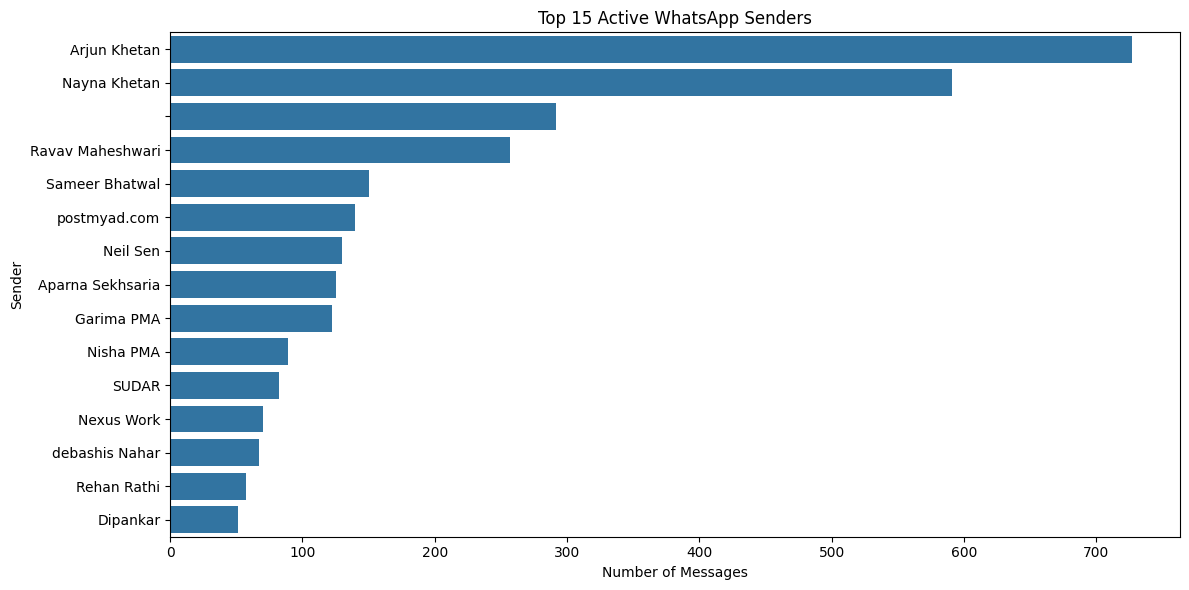

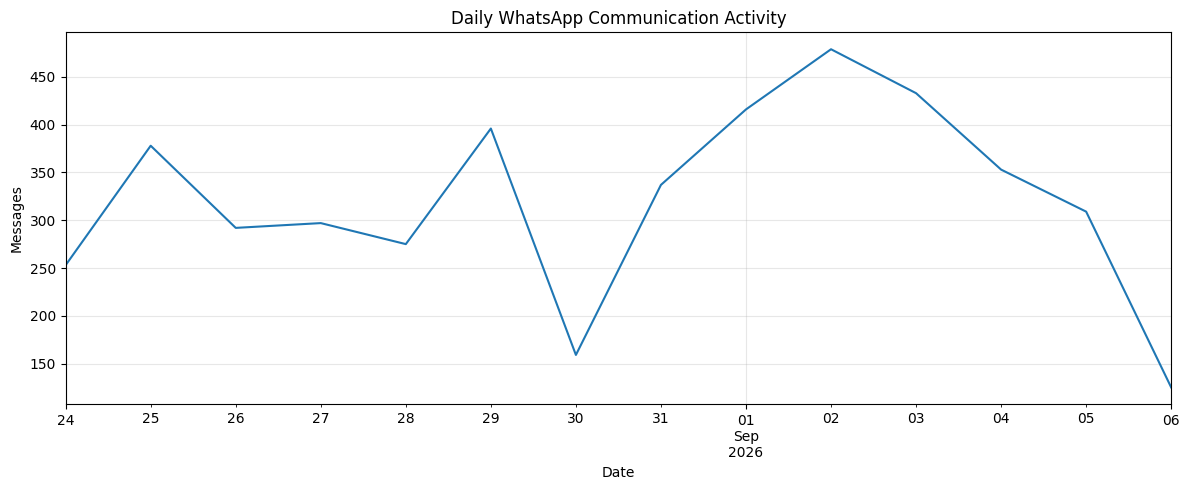

In [110]:

import matplotlib.pyplot as plt
import seaborn as sns

# Message activity by sender
sender_counts = (
    messages_df["sender_name"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=sender_counts.values,
    y=sender_counts.index
)

plt.title("Top 15 Active WhatsApp Senders")
plt.xlabel("Number of Messages")
plt.ylabel("Sender")
plt.tight_layout()
plt.show()


# Daily message activity
daily_counts = (
    messages_df
    .set_index("datetime")
    .resample("D")
    .size()
)

plt.figure(figsize=(12, 5))
daily_counts.plot()
plt.title("Daily WhatsApp Communication Activity")
plt.xlabel("Date")
plt.ylabel("Messages")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [111]:

# Create person-level communication features

person_features = []

for person_id, group in messages_df[
    messages_df["sender_id"] != "ME"
].groupby("sender_id"):

    person_name = group["sender_name"].mode()

    person_features.append({
        "person_id": person_id,
        "person_name": (
            person_name.iloc[0]
            if not person_name.empty else "Unknown"
        ),
        "message_count": len(group),
        "unique_chats": group["chat_id"].nunique(),
        "text_messages": (group["kind"] == "text").sum(),
        "image_messages": (group["kind"] == "image_caption").sum(),
        "document_messages": (group["kind"] == "document").sum(),
        "avg_message_length": group["body"].str.len().mean()
    })

person_features_df = pd.DataFrame(person_features)

person_features_df = person_features_df.sort_values(
    "message_count",
    ascending=False
)

display(person_features_df.head(20))

print("Total people analysed:", len(person_features_df))


,person_id,person_name,message_count,unique_chats,text_messages,image_messages,document_messages,avg_message_length
42,P13,Nayna Khetan,591,18,525,64,2,33.950931
220,P39,Ravav Maheshwari,257,4,233,24,0,107.447471
6,P07,,223,1,218,5,0,599.565022
1,P02,Sameer Bhatwal,150,3,144,6,0,88.773333
97,P18,Neil Sen,130,2,127,0,3,12.600000
4,P05,Aparna Sekhsaria,125,2,99,22,4,45.872000
163,P24,Garima PMA,122,2,82,23,17,28.581967
75,P16,postmyad.com,111,3,77,22,12,46.423423
234,P53,Nisha PMA,89,3,66,22,1,26.303371
9,P10,SUDAR,82,6,82,0,0,17.500000


Total people analysed: 281


In [112]:


person_chat_mapping = []

for _, chat in chats_df.iterrows():

    participants = chat.get("participants", [])

    if not isinstance(participants, list):
        participants = []

    for participant in participants:

        if not participant or participant == "ME":
            continue

        person_chat_mapping.append({
            "person_id": str(participant),
            "chat_id": str(chat["chat_id"]),
            "chat_name": str(chat.get("name", "")),
            "is_group": bool(chat.get("is_group", False))
        })


person_chat_df = pd.DataFrame(person_chat_mapping)

if not person_chat_df.empty:

    relationship_features = (
        person_chat_df
        .groupby("person_id")
        .agg(
            total_chats=("chat_id", "nunique"),
            group_chats=("is_group", "sum"),
            chat_names=("chat_name", list)
        )
        .reset_index()
    )

    relationship_features["individual_chats"] = (
        relationship_features["total_chats"]
        - relationship_features["group_chats"]
    )

else:
    relationship_features = pd.DataFrame(
        columns=[
            "person_id", "total_chats",
            "group_chats", "chat_names",
            "individual_chats"
        ]
    )


print("Participant mapping complete.")
print("Person-chat relationships:", len(person_chat_df))

display(relationship_features.head(20))


Participant mapping complete.
Person-chat relationships: 425


,person_id,total_chats,group_chats,chat_names,individual_chats
0,P01,3,2,"[BVF, Nirant Vakil, Birla House]",1
1,P02,3,3,"[BVF, Table Tennis - Bhowanipore DB, Birla House]",0
2,P03,1,1,[Lazzzy Agri pickle ball group],0
3,P04,1,1,[Lazzzy Agri pickle ball group],0
4,P05,2,2,"[PMA Operations, Acq. Rate group]",0
5,P06,5,5,"[D2C Circle 4, D2B Connect Marketplaces, D2C C...",0
6,P07,1,0,[mediadomain4],1
7,P08,1,1,[Carpool],0
8,P09,1,0,[Pradip Ghosh],1
9,P10,6,5,"[PMA Operations, Radiant operations, Nexus: Fi...",1


In [113]:

# Basic topic keyword exploration

topic_keywords = {
    "business": [
        "business", "client", "company",
        "meeting", "office", "project"
    ],
    "finance": [
        "payment", "money", "bank",
        "invoice", "amount", "budget"
    ],
    "family": [
        "family", "home", "mother",
        "father", "kids", "school"
    ],
    "planning": [
        "plan", "schedule", "tomorrow",
        "meeting", "visit", "travel"
    ],
    "tasks": [
        "send", "complete", "pending",
        "update", "follow", "remind"
    ]
}

topic_results = []

for _, msg in messages_df.iterrows():

    body = str(msg["body"]).lower()

    for topic, keywords in topic_keywords.items():

        matched = [
            word for word in keywords
            if word in body
        ]

        if matched:

            topic_results.append({
                "message_id": msg["id"],
                "chat_id": msg["chat_id"],
                "sender": msg["sender_name"],
                "topic": topic,
                "matched_keywords": matched,
                "message": body[:200]
            })

topic_df = pd.DataFrame(topic_results)

print("Topic distribution:")

display(topic_df["topic"].value_counts())

print("\nSample topic messages:")

display(topic_df.head(20))


Topic distribution:


,count
topic,
tasks,172
business,167
finance,150
planning,129
family,99



Sample topic messages:


,message_id,chat_id,sender,topic,matched_keywords,message
0,M00001,C01,Nirant Vakil,finance,[bank],wow! no listed bank has even 1% net npa\n\nhtt...
1,M00002,C01,Sameer Bhatwal,finance,[bank],even if banks double in 6 months it won't be e...
2,M00008,C04,Amish Choraria,tasks,[update],concluded our first ai summit successfully at ...
3,M00010,C06,Bhavna Budhrani,family,[father],my father in law was asking me to give blood
4,M00014,C07,Pradip Ghosh Pickleball,finance,[bank],hi \n\nsuku da will come today afternoon from ...
5,M00014,C07,Pradip Ghosh Pickleball,family,[home],hi \n\nsuku da will come today afternoon from ...
6,M00015,C07,Pradip Ghosh Pickleball,planning,[plan],main material order i placed bcoz those comes ...
7,M00021,C05,,business,[company],*polaris shifts 60% of advertising spend to di...
8,M00024,C05,,finance,[budget],*from ₹1.2 lakh budgets to the big screen: msm...
9,M00026,C07,Pradip Ghosh Pickleball,planning,"[plan, tomorrow]","today evening suku da may get late a bit, i me..."


In [114]:

OUTPUT_DIR = Path("artifacts")
OUTPUT_DIR.mkdir(exist_ok=True)

person_features_df.to_csv(
    OUTPUT_DIR / "person_features.csv",
    index=False
)

relationship_features.to_csv(
    OUTPUT_DIR / "relationship_features.csv",
    index=False
)

topic_df.to_csv(
    OUTPUT_DIR / "topic_analysis.csv",
    index=False
)

# Save structured analysis
analysis_summary = {
    "total_chats": int(len(chats_df)),
    "total_messages": int(len(messages_df)),
    "total_people": int(len(person_features_df)),
    "group_chats": int(chats_df["is_group"].sum()),
    "individual_chats": int((~chats_df["is_group"]).sum())
}

with open(
    OUTPUT_DIR / "analysis_summary.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        analysis_summary,
        file,
        indent=4
    )

print("All analysis files exported successfully!")

for file in OUTPUT_DIR.iterdir():
    print(file.name)


All analysis files exported successfully!
master_extraction.json
goal_summary.csv
open_loop_candidates.csv
owner_goal_candidates.csv
task_ownership.csv
person_organisation_links.json
open_loop_quality_audit.csv
open_loop_status.json
person_features.csv
relationship_evidence.csv
relationship_quality_audit.csv
relationship_evidence_v2.csv
open_loop_conversation_context.csv
relationship_features.csv
topic_analysis.csv
evidence_audit.csv
organisation_evidence.csv
analysis_summary.json
where_to_help_candidates.csv
task_summary.csv
starter_backup
person_contexts.jsonl
person_llm_context.jsonl
person_messages.jsonl
chat_mapping_candidates.csv


In [115]:

# Build a context profile for every person

person_contexts = []

for _, person in person_features_df.iterrows():

    person_id = person["person_id"]

    # Find all chats where this person participates
    related_chats = person_chat_df[
        person_chat_df["person_id"] == person_id
    ]

    chat_ids = related_chats["chat_id"].unique().tolist()

    # Collect messages from those conversations
    context_messages = messages_df[
        messages_df["chat_id"].isin(chat_ids)
    ].sort_values("ts")

    # Keep a manageable number of recent messages
    recent_messages = context_messages.tail(30)

    conversation_context = []

    for _, msg in recent_messages.iterrows():

        conversation_context.append({
            "message_id": msg["id"],
            "sender": msg["sender_name"],
            "sender_id": msg["sender_id"],
            "message": str(msg["body"])[:300],
            "date": str(msg["datetime"])
        })

    person_contexts.append({

        "person_id": person_id,

        "person_name": person["person_name"],

        "message_count": int(person["message_count"]),

        "total_chats": int(len(chat_ids)),

        "chat_names": related_chats[
            "chat_name"
        ].unique().tolist(),

        "conversation_context": conversation_context
    })


print("People profiles created:", len(person_contexts))

# Display one sample profile
display(person_contexts[0])


People profiles created: 281


{'person_id': 'P13',
 'person_name': 'Nayna Khetan',
 'message_count': 591,
 'total_chats': 18,
 'chat_names': ['Carpool',
  'Nayna Khetan',
  'Radiant operations',
  'Summer',
  'Khetans and Rathores',
  'Italy 2014',
  'Home is where the Heart is',
  'Family 👪',
  'project coffee table book',
  'Morsel & Roll & Maki / SMM',
  '7A &5b Kanchan : Debjani',
  'I Love my Family 🇮🇳❤️',
  'Ratekar family',
  'Birla House',
  'Siblings ❤',
  'Nerds',
  'Tadoba feb',
  'Kitchen 5c 🥕🥒\U0001fadc 🍌🍍🥭🍎🍅🍓🍋\u200d🟩🥑🫐🍇\U0001fadc🍄\u200d🟫🍞🥚🥐🧇🍟🍕🍭🍿🍪🍴🍽️🍹🧁(logo by dev)'],
 'conversation_context': [{'message_id': 'M04418',
   'sender': 'Rituparna Vakil',
   'sender_id': 'P220',
   'message': 'https://www.instagram.com/reel/Ed4ZGcFrhaF/?stkn=cHZzaWNudTRrcnQ2',
   'date': '2026-09-06 05:46:23+00:00'},
  {'message_id': 'M04421',
   'sender': 'Rekha Charu Maheshwari',
   'sender_id': 'P51',
   'message': 'We',
   'date': '2026-09-06 05:57:36+00:00'},
  {'message_id': 'M04422',
   'sender': 'Nayna Khetan',
   's

In [116]:

import re

relationship_patterns = {

    "spouse": [
        r"\bmy husband\b",
        r"\bmy wife\b",
        r"\bhusband\b",
        r"\bwife\b"
    ],

    "parent": [
        r"\bmy mother\b",
        r"\bmy father\b",
        r"\bmom\b",
        r"\bdad\b"
    ],

    "child": [
        r"\bmy son\b",
        r"\bmy daughter\b",
        r"\bkids\b"
    ],

    "sibling": [
        r"\bmy brother\b",
        r"\bmy sister\b",
        r"\bsibling\b"
    ],

    "relative": [
        r"\bcousin\b",
        r"\buncle\b",
        r"\baunt\b",
        r"\brelative\b"
    ],

    "colleague": [
        r"\bteam member\b",
        r"\bcolleague\b",
        r"\bcoworker\b",
        r"\boffice team\b"
    ],

    "client": [
        r"\bclient\b",
        r"\bcustomer\b",
        r"\bcustomer meeting\b"
    ],

    "vendor": [
        r"\bsupplier\b",
        r"\bvendor\b",
        r"\bquotation\b"
    ],

    "friend": [
        r"\bmy friend\b",
        r"\bbest friend\b"
    ]
}


def extract_relationship_signals(text):

    text = str(text).lower()

    detected = []

    for relationship, patterns in relationship_patterns.items():

        for pattern in patterns:

            if re.search(pattern, text):

                detected.append(relationship)
                break

    return detected


relationship_evidence = []

for profile in person_contexts:

    for message in profile["conversation_context"]:

        detected = extract_relationship_signals(
            message["message"]
        )

        if detected:

            relationship_evidence.append({

                "person_id": profile["person_id"],

                "person_name": profile["person_name"],

                "message_id": message["message_id"],

                "message": message["message"],

                "detected_relationships": detected
            })


relationship_evidence_df = pd.DataFrame(
    relationship_evidence
)

print("Relationship evidence found:",
      len(relationship_evidence_df))

display(relationship_evidence_df.head(20))


Relationship evidence found: 167


,person_id,person_name,message_id,message,detected_relationships
0,P13,Nayna Khetan,M04437,Lmk what time to pick kids from bca. Will take...,[child]
1,P41,Dipankar,M04145,"Don't quote pl, customer has no budget",[client]
2,P65,Suparna Office,M03348,"Hi Reddy, we just need ur creatives + budget i...",[client]
3,P35,Samata,M04145,"Don't quote pl, customer has no budget",[client]
4,P09,Pradip Ghosh Pickleball,M00566,I think as the basketball court is smaller tha...,[child]
5,P26,Arar Bagri,M04160,That's almost certainly about the Catalog feed...,[relative]
6,P26,Arar Bagri,M04163,Maximum of 4 images sent to customer. Based on...,[client]
7,P68,Mr. Irfan,M04356,Happy Teachers day to all the lovely mothers w...,"[spouse, child]"
8,P45,Aman Bhatia,M04356,Happy Teachers day to all the lovely mothers w...,"[spouse, child]"
9,P229,Roopa Jajodia,M03160,A little urgent for us to know if you are avai...,[client]


In [117]:

# Load known relationships from user-provided seed

known_circles = seed_data.get("circles", {})

print("Known relationships from seed:\n")

for person_id, circle in known_circles.items():

    print(person_id, "->", circle)


# Create a lookup for known person labels
seed_circle_lookup = {
    person_id: circle
    for person_id, circle in known_circles.items()
}

# Add seed information to person features
person_features_df["known_circle"] = (
    person_features_df["person_id"]
    .map(seed_circle_lookup)
)

person_features_df["is_known_person"] = (
    person_features_df["known_circle"].notna()
)

display(
    person_features_df[
        ["person_id", "person_name",
         "message_count", "known_circle",
         "is_known_person"]
    ].head(20)
)


Known relationships from seed:

P18 -> colleague
P31 -> relative
P269 -> client
P136 -> vendor
P212 -> colleague
P319 -> partner
P239 -> client
P34 -> parent
P76 -> sibling
P117 -> friend


,person_id,person_name,message_count,known_circle,is_known_person
42,P13,Nayna Khetan,591,NaN,False
220,P39,Ravav Maheshwari,257,NaN,False
6,P07,,223,NaN,False
1,P02,Sameer Bhatwal,150,NaN,False
97,P18,Neil Sen,130,colleague,True
4,P05,Aparna Sekhsaria,125,NaN,False
163,P24,Garima PMA,122,NaN,False
75,P16,postmyad.com,111,NaN,False
234,P53,Nisha PMA,89,NaN,False
9,P10,SUDAR,82,NaN,False


In [118]:

# Export contextual profiles and relationship evidence

with open(
    OUTPUT_DIR / "person_contexts.jsonl",
    "w",
    encoding="utf-8"
) as file:

    for profile in person_contexts:

        file.write(
            json.dumps(
                profile,
                ensure_ascii=False
            ) + "\n"
        )


relationship_evidence_df.to_csv(
    OUTPUT_DIR / "relationship_evidence.csv",
    index=False
)

person_features_df.to_csv(
    OUTPUT_DIR / "person_features.csv",
    index=False
)

print("People intelligence files exported.")

print("\nAvailable files:")

for file in OUTPUT_DIR.iterdir():
    print(file.name)


People intelligence files exported.

Available files:
master_extraction.json
goal_summary.csv
open_loop_candidates.csv
owner_goal_candidates.csv
task_ownership.csv
person_organisation_links.json
open_loop_quality_audit.csv
open_loop_status.json
person_features.csv
relationship_evidence.csv
relationship_quality_audit.csv
relationship_evidence_v2.csv
open_loop_conversation_context.csv
relationship_features.csv
topic_analysis.csv
evidence_audit.csv
organisation_evidence.csv
analysis_summary.json
where_to_help_candidates.csv
task_summary.csv
starter_backup
person_contexts.jsonl
person_llm_context.jsonl
person_messages.jsonl
chat_mapping_candidates.csv


In [119]:
from pathlib import Path

# Starter kit ke important files
files_to_check = [
    "llm.py",
    "solution.py",
    "schema.json",
    "README.md"
]

for filename in files_to_check:
    file_path = Path(filename)

    print("\n" + "=" * 60)
    print("FILE:", filename)
    print("=" * 60)

    if file_path.exists():
        content = file_path.read_text(encoding="utf-8")
        print(content[:8000])
    else:
        print("File nahi mili:", file_path)


FILE: llm.py
"""A tiny client for any OpenAI-compatible chat API, standard library only.

It reads LLM_BASE_URL, LLM_API_KEY and LLM_MODEL from the environment, which is how we run your
code with our own key when we score it. Every call appends its token counts to usage.jsonl, so you
can see what a run costs before we do.

    from llm import chat
    reply = chat([{"role": "user", "content": "Hello"}])

You don't have to use this file. Any client is fine, as long as it reads those three variables and
sends nothing anywhere else.
"""
import json
import os
import time
import urllib.request


def chat(messages, model=None, temperature=0, max_tokens=None, response_format=None, timeout=120):
    base = os.environ["LLM_BASE_URL"].rstrip("/")
    body = {"model": model or os.environ["LLM_MODEL"], "messages": messages, "temperature": temperature}
    if max_tokens:
        body["max_tokens"] = max_tokens
    if response_format:
        body["response_format"] = response_format
    req = urll

In [120]:

import json
from pathlib import Path
from collections import defaultdict

person_messages = defaultdict(list)

for _, chat in chats_df.iterrows():

    chat_id = str(chat["chat_id"])
    participants = chat.get("participants", [])

    if not isinstance(participants, list):
        continue

    # ME ko person list se remove karo
    participants = [
        str(p) for p in participants
        if p and str(p) != "ME"
    ]

    chat_messages = messages_df[
        messages_df["chat_id"].astype(str) == chat_id
    ].sort_values("ts")

    # Har actual participant ke liye chat context
    for person_id in participants:

        for _, msg in chat_messages.iterrows():

            body = str(msg["body"]).strip()

            if not body:
                continue

            person_messages[person_id].append({
                "chat_id": chat_id,
                "message_id": str(msg["id"]),
                "sender_id": str(msg["sender_id"]),
                "text": body,
                "timestamp": str(msg["datetime"])
            })


output_path = Path("artifacts/person_llm_context.jsonl")
output_path.parent.mkdir(parents=True, exist_ok=True)

with output_path.open("w", encoding="utf-8") as f:

    for person_id, records in person_messages.items():

        # Recent context only
        records = records[-100:]

        profile = {
            "person_id": person_id,
            "known_circle": seed_data.get(
                "circles", {}
            ).get(person_id),
            "messages": records
        }

        f.write(
            json.dumps(profile, ensure_ascii=False) + "\n"
        )


print("Person contexts:", len(person_messages))
print("ME included:", "ME" in person_messages)
print("Saved:", output_path)


Person contexts: 286
ME included: False
Saved: artifacts/person_llm_context.jsonl


In [121]:
import json
from pathlib import Path

# Person-wise context file load karo
context_path = Path("artifacts/person_llm_context.jsonl")

person_contexts = []

if context_path.exists():
    with context_path.open("r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                person_contexts.append(json.loads(line))

print("Total person contexts:", len(person_contexts))

if len(person_contexts) == 0:
    print("\n[WARNING] No contexts found in the file! Please run cell O6Gd3U9W2X5k with corrected column names first:")
    print("Use 'id' instead of 'message_id', 'ts' instead of 'timestamp', and 'body' instead of 'text'.")
else:
    # Ek person ka example select karo
    sample_person = person_contexts[0]

    person_id = sample_person["person_id"]
    messages = sample_person["messages"]

    # Messages ko readable format mein convert karo
    conversation = []

    for msg in messages[-40:]:
        conversation.append({
            "message_id": msg.get("message_id", msg.get("id", "")),
            "sender_id": msg["sender_id"],
            "text": msg.get("text", msg.get("body", ""))
        })

    # LLM prompt
    prompt = f"""
    You are a personal context analysis assistant.

    Your task is to understand the relationship between the user
    and another person using WhatsApp conversation evidence.

    PERSON ID:
    {person_id}

    CONVERSATION:
    {json.dumps(conversation, ensure_ascii=False, indent=2)}

    TASK:
    1. Identify the likely relationship between the user and this person.
    2. Use only evidence present in the conversation.
    3. Do not assume a relationship based on a single generic word.
    4. Distinguish messages written by the user from messages written
       by the other person using sender_id.
    5. If evidence is insufficient, return "unknown".
    6. Never invent names, organisations, or personal details.

    Return ONLY valid JSON in this format:

    {{
        "person_id": "{person_id}",
        "circle": "colleague",
        "confidence": 0.0,
        "evidence": [
            {{
                "message_id": "message_id_here",
                "reason": "Why this message supports the relationship"
            }}
        ]
    }}

    Confidence must be between 0 and 1.
    If the relationship is unknown, use an empty evidence list.
    """
    print(prompt)

Total person contexts: 286

    You are a personal context analysis assistant.

    Your task is to understand the relationship between the user
    and another person using WhatsApp conversation evidence.

    PERSON ID:
    P01

    CONVERSATION:
    [
  {
    "message_id": "M03282",
    "sender_id": "P177",
    "text": "Happy 40th Zara!! 💥"
  },
  {
    "message_id": "M03291",
    "sender_id": "P117",
    "text": "Happy Happy 40th @219384756102938"
  },
  {
    "message_id": "M03292",
    "sender_id": "P221",
    "text": "Happy happy 40th Zara!!! 🎉🎉"
  },
  {
    "message_id": "M03293",
    "sender_id": "P51",
    "text": "Happy happy 40th Zara! Hope it's fantastic ❤️"
  },
  {
    "message_id": "M03294",
    "sender_id": "P210",
    "text": "Happy Birthday Zara 🤗🎉"
  },
  {
    "message_id": "M03295",
    "sender_id": "P220",
    "text": "Happy 40th Zara! 💫"
  },
  {
    "message_id": "M03296",
    "sender_id": "P02",
    "text": "Happy bday 🍾🍾"
  },
  {
    "message_id": "M03297",

In [122]:
from pathlib import Path

# LLM integration ka exact interface check karna
llm_file = Path("llm.py")

if llm_file.exists():
    print(llm_file.read_text(encoding="utf-8"))
else:
    print("llm.py nahi mila. Current folder:", Path.cwd())

"""A tiny client for any OpenAI-compatible chat API, standard library only.

It reads LLM_BASE_URL, LLM_API_KEY and LLM_MODEL from the environment, which is how we run your
code with our own key when we score it. Every call appends its token counts to usage.jsonl, so you
can see what a run costs before we do.

    from llm import chat
    reply = chat([{"role": "user", "content": "Hello"}])

You don't have to use this file. Any client is fine, as long as it reads those three variables and
sends nothing anywhere else.
"""
import json
import os
import time
import urllib.request


def chat(messages, model=None, temperature=0, max_tokens=None, response_format=None, timeout=120):
    base = os.environ["LLM_BASE_URL"].rstrip("/")
    body = {"model": model or os.environ["LLM_MODEL"], "messages": messages, "temperature": temperature}
    if max_tokens:
        body["max_tokens"] = max_tokens
    if response_format:
        body["response_format"] = response_format
    req = urllib.request.Req

In [123]:
import json

# Sample LLM response (sirf testing ke liye)
sample_response = {
    "person_id": "P01",
    "circle": "colleague",
    "confidence": 0.92,
    "evidence": [
        {
            "message_id": "M101",
            "reason": "The conversation contains work-related coordination."
        }
    ]
}


# Step 1: JSON serialization
json_output = json.dumps(sample_response, ensure_ascii=False, indent=4)

print("Generated JSON:")
print(json_output)


# Step 2: JSON parsing
parsed_output = json.loads(json_output)


# Step 3: Basic validation
required_fields = [
    "person_id",
    "circle",
    "confidence",
    "evidence"
]

for field in required_fields:
    assert field in parsed_output, f"Missing field: {field}"


# Step 4: Confidence validation
assert 0 <= parsed_output["confidence"] <= 1

# Step 5: Evidence validation
assert isinstance(parsed_output["evidence"], list)

for evidence in parsed_output["evidence"]:
    assert "message_id" in evidence
    assert "reason" in evidence

print("\nJSON validation successful!")

Generated JSON:
{
    "person_id": "P01",
    "circle": "colleague",
    "confidence": 0.92,
    "evidence": [
        {
            "message_id": "M101",
            "reason": "The conversation contains work-related coordination."
        }
    ]
}

JSON validation successful!


In [124]:

import re
import pandas as pd

organisation_keywords = [
    "company", "office", "organisation", "organization",
    "college", "university", "startup", "business",
    "client", "vendor", "project", "team",
    "department", "hr", "manager", "invoice", "payment"
]

organisation_candidates = []

for _, msg in messages_df.iterrows():

    text = str(msg["body"]).strip()

    if not text:
        continue

    lower_text = text.lower()

    matched = [
        word for word in organisation_keywords
        if re.search(r"\b" + re.escape(word) + r"\b", lower_text)
    ]

    if matched:
        organisation_candidates.append({
            "message_id": str(msg["id"]),
            "chat_id": str(msg["chat_id"]),
            "sender_id": str(msg["sender_id"]),
            "message": text,
            "matched_keywords": matched
        })


organisation_evidence_df = pd.DataFrame(organisation_candidates)

print("Organisation-related messages:", len(organisation_evidence_df))
display(organisation_evidence_df.head(20))


Organisation-related messages: 234


,message_id,chat_id,sender_id,message,matched_keywords
0,M00021,C05,P07,*Polaris shifts 60% of advertising spend to di...,[company]
1,M00039,C05,P07,*StreamNow isn't changing what a view is worth...,[business]
2,M00043,C05,P07,*BW Top Headlines*\n\n\n*Onam 2026: A preview ...,[business]
3,M00044,C13,P15,💰 *Payment Baki — *\n2 parties · Rs 98k\n📋 Sob...,[payment]
4,M00056,C03,P21,1996848- Please update the payment details if ...,[payment]
5,M00100,C08,P11,"*प्रवासी ओसवाल समाज से बड़ी खबर, गेहानी टीम ने...",[team]
6,M00143,C05,P07,*Nitin Kapoor joins Vega Group India as Vice P...,[manager]
7,M00144,C03,P18,need this full screnshot to match payment,[payment]
8,M00156,C03,P32,2304830 - change the statues payment received,[payment]
9,M00181,C28,P40,Looking to hire a graphic designer with 2-4yea...,[team]


In [125]:

import re
import pandas as pd

ignore_words = {
    "I", "We", "You", "He", "She", "They",
    "The", "This", "That", "Please", "Thanks",
    "Hello", "Hi", "Good", "Tomorrow", "Today",
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
}

organisation_name_candidates = []

for _, msg in messages_df.iterrows():

    text = str(msg["body"]).strip()

    if not text:
        continue

    matches = re.findall(
        r"\b[A-Z][a-zA-Z0-9&.-]*(?:\s+[A-Z][a-zA-Z0-9&.-]*){0,3}\b",
        text
    )

    for name in matches:

        name = name.strip()

        if name in ignore_words or len(name) < 3:
            continue

        organisation_name_candidates.append({
            "candidate_name": name,
            "message_id": str(msg["id"]),
            "chat_id": str(msg["chat_id"]),
            "sender_id": str(msg["sender_id"]),
            "message": text
        })


organisation_names_df = pd.DataFrame(organisation_name_candidates)

if not organisation_names_df.empty:

    frequency = (
        organisation_names_df
        .groupby("candidate_name")
        .size()
        .reset_index(name="frequency")
        .sort_values("frequency", ascending=False)
    )

    display(frequency.head(30))

else:
    print("No organisation name candidates found.")


,candidate_name,frequency
2249,Nexus,208
2727,Read,207
929,Done,116
1557,India,113
3605,What,82
1346,Happy,75
2728,Read More,71
3358,These,54
93,Advantage,54
3316,Thank,49


In [126]:

import pandas as pd

role_keywords = {
    "employee": [
        "work at", "working at", "employee",
        "joined", "office", "my company"
    ],
    "client": [
        "client", "customer", "our project",
        "your project"
    ],
    "vendor": [
        "vendor", "supplier", "delivery", "invoice"
    ],
    "partner": [
        "business partner", "partnership", "partner"
    ],
    "founder": [
        "founder", "co-founder",
        "started the company", "my startup"
    ]
}

person_org_evidence = []

for _, msg in messages_df.iterrows():

    text = str(msg["body"]).lower().strip()

    if not text:
        continue

    matched_roles = []

    for role, keywords in role_keywords.items():

        if any(keyword in text for keyword in keywords):
            matched_roles.append(role)

    if matched_roles:

        person_org_evidence.append({
            "person_id": str(msg["sender_id"]),
            "message_id": str(msg["id"]),
            "chat_id": str(msg["chat_id"]),
            "possible_roles": matched_roles,
            "message": str(msg["body"])
        })


person_org_df = pd.DataFrame(person_org_evidence)

print("Person-organisation evidence:", len(person_org_df))
display(person_org_df.head(20))


Person-organisation evidence: 173


,person_id,message_id,chat_id,possible_roles,message
0,P07,M00039,C05,[partner],*StreamNow isn't changing what a view is worth...
1,P16,M00048,C03,[client],8510482 + 3123032 @Customer Care Plz check and...
2,ME,M00060,C17,[vendor],its fine. let it stabilize initial 1-2 weeks i...
3,P23,M00061,C18,[founder],*SurarX: A Launchpad SurarTech Event*\n\nWe wi...
4,ME,M00164,C17,[client],for sales data i think its missing the custome...
5,P22,M00166,C17,[client],Can it be mapped against order Id and customer...
6,P07,M00182,C05,[partner],*New Zealand proposes social media ban for und...
7,P07,M00259,C05,"[employee, client]",*Fletcher's appoints Marcus Webb as Chief Mark...
8,P07,M00263,C05,[client],*D2C brands look beyond ROAS as rising CAC put...
9,P07,M00272,C05,"[employee, client]",*BW Top Headlines*\n\n*TV inventory is selling...


In [127]:

import re
import pandas as pd

goal_patterns = {
    "work": [
        r"\bi want to get a job\b",
        r"\bi am looking for an internship\b",
        r"\bi want to apply\b",
        r"\bi want to grow my business\b",
        r"\bi want to build my career\b"
    ],
    "self": [
        r"\bi want to learn\b",
        r"\bi want to improve\b",
        r"\bi want to develop\b",
        r"\bi want to become\b"
    ],
    "health": [
        r"\bi want to get fit\b",
        r"\bi want to lose weight\b",
        r"\bi want to improve my health\b"
    ],
    "finances": [
        r"\bi want to save money\b",
        r"\bi want to invest\b",
        r"\bi want to pay off\b"
    ],
    "experiences": [
        r"\bi want to travel\b",
        r"\bi want to visit\b",
        r"\bi want to explore\b"
    ],
    "home": [
        r"\bi want to renovate\b",
        r"\bi want to buy a house\b"
    ]
}

# Goal messages should come from ME
owner_messages = messages_df[
    messages_df["sender_id"] == "ME"
].copy()

goal_candidates = []

for _, msg in owner_messages.iterrows():

    text = str(msg["body"]).strip()
    lower_text = text.lower()

    if not text:
        continue

    for area, patterns in goal_patterns.items():

        matched = [
            p for p in patterns
            if re.search(p, lower_text)
        ]

        if matched:

            goal_candidates.append({
                "message_id": str(msg["id"]),
                "chat_id": str(msg["chat_id"]),
                "sender_id": "ME",
                "area": area,
                "matched_patterns": matched,
                "message": text
            })


goal_evidence_df = pd.DataFrame(goal_candidates)

print("Goal candidates:", len(goal_evidence_df))
display(goal_evidence_df.head(25))


Goal candidates: 0


""


In [128]:


import re
import pandas as pd

open_loop_patterns = {
    "request": [
        r"\bplease send\b",
        r"\bcan you send\b",
        r"\bcould you share\b",
        r"\bplease share\b",
        r"\bplease confirm\b",
        r"\bcan you check\b"
    ],
    "commitment": [
        r"\bi will send\b",
        r"\bi'll send\b",
        r"\bi will share\b",
        r"\bi'll share\b",
        r"\bi will call\b",
        r"\bi will update\b"
    ],
    "follow_up": [
        r"\bfollow up\b",
        r"\bfollow-up\b",
        r"\bremind me\b",
        r"\bwaiting for\b",
        r"\bnot received\b",
        r"\bawaiting\b"
    ],
    "deadline": [
        r"\bby tomorrow\b",
        r"\bby today\b",
        r"\bdue tomorrow\b",
        r"\bbefore the deadline\b"
    ]
}

open_loop_candidates = []

for _, msg in messages_df.iterrows():

    text = str(msg["body"]).strip()
    lower_text = text.lower()

    if not text:
        continue

    for task_type, patterns in open_loop_patterns.items():

        matched = [
            p for p in patterns
            if re.search(p, lower_text)
        ]

        if matched:

            open_loop_candidates.append({
                "message_id": str(msg["id"]),
                "chat_id": str(msg["chat_id"]),
                "sender_id": str(msg["sender_id"]),
                "sender_name": str(msg["sender_name"]),
                "datetime": msg["datetime"],
                "task_type": task_type,
                "matched_patterns": matched,
                "message": text
            })


open_loops_df = pd.DataFrame(open_loop_candidates)

print("Open-loop candidates:", len(open_loops_df))
display(open_loops_df.head(30))


Open-loop candidates: 38


,message_id,chat_id,sender_id,sender_name,datetime,task_type,matched_patterns,message
0,M00083,C22,P27,Tarun Sayan India,2026-08-24 07:26:17+00:00,request,[\bplease share\b],"Guys, please share those pictures again from G..."
1,M00092,C24,P29,Nexus Work,2026-08-24 07:41:17+00:00,follow_up,[\bawaiting\b],"Hello @835997309919066 @213092110597887 , a ve..."
2,M00135,C26,P33,Ramita Biren,2026-08-24 08:56:00+00:00,request,[\bplease send\b],Please send me your child's name and date of b...
3,M00163,C21,ME,Arjun Khetan,2026-08-24 10:23:15+00:00,follow_up,[\bfollow-up\b],What went live:\nproduct-specific first replie...
4,M00328,C40,P29,Nexus Work,2026-08-25 07:23:48+00:00,request,[\bcould you share\b],"Hi @85899424168731, could you share what is th..."
5,M00356,C03,P05,Aparna Sekhsaria,2026-08-25 08:12:55+00:00,request,[\bplease send\b],Payment done. Please send invoices.
6,M00758,C40,P29,Nexus Work,2026-08-26 08:32:31+00:00,request,[\bcould you share\b],"@269183361899381 , could you share your email ..."
7,M00963,C58,P65,Suparna Office,2026-08-27 05:11:34+00:00,request,[\bplease share\b],Please share your company name address and GST...
8,M01136,C58,P65,Suparna Office,2026-08-27 10:57:53+00:00,request,[\bplease share\b],@241680869932636 please share the estimate bas...
9,M01144,C03,P18,Neil Sen,2026-08-27 11:16:41+00:00,follow_up,[\bnot received\b],not received yet


In [129]:

import re
import pandas as pd

completion_patterns = [
    r"\bdone\b",
    r"\bcompleted\b",
    r"\bsent it\b",
    r"\bshared it\b",
    r"\bsubmitted\b",
    r"\buploaded\b",
    r"\bdelivered\b",
    r"\bresolved\b",
    r"\bpayment received\b",
    r"\bbooked successfully\b"
]

completion_evidence = []

for _, msg in messages_df.iterrows():

    text = str(msg["body"]).strip()
    lower_text = text.lower()

    if not text:
        continue

    matched = [
        p for p in completion_patterns
        if re.search(p, lower_text)
    ]

    if matched:

        completion_evidence.append({
            "message_id": str(msg["id"]),
            "chat_id": str(msg["chat_id"]),
            "sender_id": str(msg["sender_id"]),
            "datetime": msg["datetime"],
            "message": text,
            "completion_patterns": matched
        })


completion_df = pd.DataFrame(completion_evidence)

print("Completion candidates:", len(completion_df))
display(completion_df.head(25))


Completion candidates: 183


,message_id,chat_id,sender_id,datetime,message,completion_patterns
0,M00053,C03,P18,2026-08-24 05:57:15+00:00,Done,[\bdone\b]
1,M00061,C18,P23,2026-08-24 06:37:36+00:00,*SurarX: A Launchpad SurarTech Event*\n\nWe wi...,[\bdone\b]
2,M00063,C03,P18,2026-08-24 06:42:46+00:00,Done,[\bdone\b]
3,M00064,C05,P07,2026-08-24 06:49:58+00:00,*Onam 2026 is shaping up as a test run for the...,[\bcompleted\b]
4,M00067,C03,P18,2026-08-24 06:53:29+00:00,Done,[\bdone\b]
5,M00084,C03,P18,2026-08-24 07:27:14+00:00,Done,[\bdone\b]
6,M00127,C10,ME,2026-08-24 08:55:01+00:00,Wed -2-6 if ur avail. adhd test can be done.,[\bdone\b]
7,M00153,C03,P18,2026-08-24 09:51:40+00:00,Done,[\bdone\b]
8,M00156,C03,P32,2026-08-24 10:02:51+00:00,2304830 - change the statues payment received,[\bpayment received\b]
9,M00157,C03,P18,2026-08-24 10:03:36+00:00,done,[\bdone\b]


In [130]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

task_matches = []

if not open_loops_df.empty and not completion_df.empty:

    pending_texts = open_loops_df["message"].fillna("").tolist()
    completed_texts = completion_df["message"].fillna("").tolist()

    vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )

    all_texts = pending_texts + completed_texts
    tfidf_matrix = vectorizer.fit_transform(all_texts)

    pending_vectors = tfidf_matrix[:len(pending_texts)]
    completed_vectors = tfidf_matrix[len(pending_texts):]

    similarity_matrix = cosine_similarity(
        pending_vectors,
        completed_vectors
    )

    for i in range(len(pending_texts)):

        task = open_loops_df.iloc[i]

        for j in range(len(completed_texts)):

            completion = completion_df.iloc[j]

            # Same chat and completion must be later
            if task["chat_id"] != completion["chat_id"]:
                continue

            if completion["datetime"] <= task["datetime"]:
                continue

            score = similarity_matrix[i][j]

            if score >= 0.15:

                task_matches.append({
                    "pending_message_id": task["message_id"],
                    "completion_message_id": completion["message_id"],
                    "chat_id": task["chat_id"],
                    "similarity_score": round(float(score), 3),
                    "pending_message": pending_texts[i],
                    "completion_message": completed_texts[j]
                })


task_matches_df = pd.DataFrame(task_matches)

print("Potential task matches:", len(task_matches_df))
display(task_matches_df.head(20))


Potential task matches: 6


,pending_message_id,completion_message_id,chat_id,similarity_score,pending_message,completion_message
0,M00356,M02995,C03,1.000,Payment done. Please send invoices.,Payment done.\nPlease send invoices.
1,M01144,M02606,C03,0.227,not received yet,9001774- Please change the ad status as paymen...
2,M01144,M03006,C03,0.169,not received yet,9030338- Please ad the apl of 350 and update t...
3,M01144,M03677,C03,0.227,not received yet,5031024- Please change the ad status as paymen...
4,M01144,M03776,C03,0.227,not received yet,1416594- Please change the ad status as paymen...
5,M01144,M04220,C03,0.223,not received yet,3760867 - pls make the statues payment received


In [131]:

import pandas as pd

help_patterns = {
    "reminder": [
        "remind me", "don't forget",
        "keep forgetting", "due tomorrow"
    ],
    "drafting": [
        "draft an email", "write an email",
        "help me write", "prepare a message",
        "reply to"
    ],
    "follow_up": [
        "waiting for response", "no reply",
        "follow up", "haven't heard back"
    ],
    "planning": [
        "help me plan", "how should i",
        "need a plan", "not sure how to"
    ],
    "research": [
        "find information", "research about",
        "compare options", "need details"
    ]
}

help_candidates = []

for _, msg in messages_df.iterrows():

    text = str(msg["body"]).strip()
    lower_text = text.lower()

    if not text:
        continue

    for help_type, keywords in help_patterns.items():

        matched = [
            word for word in keywords
            if word in lower_text
        ]

        if matched:

            help_candidates.append({
                "message_id": str(msg["id"]),
                "chat_id": str(msg["chat_id"]),
                "sender_id": str(msg["sender_id"]),
                "help_type": help_type,
                "matched_keywords": matched,
                "message": text
            })


help_df = pd.DataFrame(help_candidates)

print("Help candidates:", len(help_df))
display(help_df.head(30))


Help candidates: 4


,message_id,chat_id,sender_id,help_type,matched_keywords,message
0,M01873,C09,ME,reminder,[remind me],coming week need all my scanned docs from moha...
1,M02044,C10,ME,drafting,[reply to],just reply to it. that change to this. even AI...
2,M02279,C94,P26,planning,[how should i],Also I have stared to make the catelog!! Show ...
3,M03999,C35,P259,follow_up,[follow up],I have good 7 years of experience in business ...


In [132]:
import json
from pathlib import Path

# All results ko ek dictionary mein combine karna
master_results = {

    "dataset_summary": {
        "total_chats": int(len(chats_df)),
        "total_messages": int(len(messages_df))
    },

    "people": {
        "total_people": int(len(person_features_df)),
        "relationship_evidence": (
            relationship_evidence_df.to_dict(orient="records")
        )
    },

    "organisations": {
        "evidence": (
            organisation_evidence_df.to_dict(orient="records")
        ),
        "name_candidates": (
            organisation_names_df.to_dict(orient="records")
            if not organisation_names_df.empty else []
        ),
        "person_roles": (
            person_org_df.to_dict(orient="records")
            if not person_org_df.empty else []
        )
    },

    "goals": (
        goal_evidence_df.to_dict(orient="records")
        if not goal_evidence_df.empty else []
    ),

    "open_loops": {
        "pending_candidates": (
            open_loops_df.to_dict(orient="records")
            if not open_loops_df.empty else []
        ),
        "completion_evidence": (
            completion_df.to_dict(orient="records")
            if not completion_df.empty else []
        ),
        "possible_matches": (
            task_matches_df.to_dict(orient="records")
            if not task_matches_df.empty else []
        )
    },

    "where_to_help": (
        help_df.to_dict(orient="records")
        if not help_df.empty else []
    )
}


# Save master JSON
output_file = Path("artifacts/master_extraction.json")
output_file.parent.mkdir(parents=True, exist_ok=True)

with output_file.open("w", encoding="utf-8") as f:
    json.dump(
        master_results,
        f,
        ensure_ascii=False,
        indent=4,
        default=str
    )


print("Master extraction completed!")
print("Saved:", output_file)
print("File size:", round(output_file.stat().st_size / 1024, 2), "KB")

Master extraction completed!
Saved: artifacts/master_extraction.json
File size: 7211.92 KB


In [133]:
import json
from pathlib import Path

schema_path = Path("schema.json")

if not schema_path.exists():
    raise FileNotFoundError(
        "schema.json nahi mila. Current folder: " + str(Path.cwd())
    )

with schema_path.open("r", encoding="utf-8") as f:
    schema = json.load(f)

print("SCHEMA CONTENT:")
print(json.dumps(schema, indent=4, ensure_ascii=False))

SCHEMA CONTENT:
{
    "$schema": "https://json-schema.org/draft/2020-12/schema",
    "title": "Cold Start output",
    "description": "What run.sh writes. Ids for people, chats and messages come from the input. Organisation ids are yours.",
    "type": "object",
    "required": [
        "people",
        "organisations",
        "chats",
        "goals",
        "open_loops"
    ],
    "additionalProperties": false,
    "properties": {
        "people": {
            "type": "array",
            "description": "One entry per person Arjun deals with. Never include ME.",
            "items": {
                "type": "object",
                "required": [
                    "id",
                    "circle"
                ],
                "additionalProperties": false,
                "properties": {
                    "id": {
                        "type": "string",
                        "description": "A person id from the input"
                    },
                    "c

In [134]:
from pathlib import Path

solution_path = Path("solution.py")

if solution_path.exists():
    print(solution_path.read_text(encoding="utf-8"))
else:
    print("solution.py nahi mila")

#!/usr/bin/env python3
"""A starting point: reads the input and writes a valid, deliberately naive output.json.

It puts everyone in the "friend" circle, makes each group chat its own organisation, ties every
1:1 chat to the other person, and finds no goals or loops. It scores badly on purpose. Replace it.

    python3 solution.py <input_dir> <output.json>
"""
import json
import sys
from pathlib import Path


def read_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def main(input_dir, output_path):
    folder = Path(input_dir)
    chats = read_jsonl(folder / "chats.jsonl")
    messages = read_jsonl(folder / "messages.jsonl")  # noqa: F841 - you'll want these

    people = sorted({p for c in chats for p in c["participants"]} - {"ME"})
    organisations, ties = [], []
    for c in chats:
        if c["is_group"]:
            org_id = "org_" + c["chat_id"]
            organisations.append({"id": org_id, "name": c["

In [135]:
from pathlib import Path
import json

print("========== PROJECT STATUS ==========")

# Important input files
input_files = [
    "data/dev/chats.jsonl",
    "data/dev/messages.jsonl",
    "data/dev/seed.json",
    "schema.json",
    "solution.py",
    "llm.py",
    "check.py"
]

print("\nINPUT FILES")

for filename in input_files:
    path = Path(filename)
    print(filename, "->", "FOUND" if path.exists() else "MISSING")


# Generated artifacts
print("\nGENERATED ARTIFACTS")

artifact_dir = Path("artifacts")

if artifact_dir.exists():
    for file in artifact_dir.iterdir():
        if file.is_file():
            print(file.name, "->", round(file.stat().st_size / 1024, 2), "KB")
else:
    print("Artifacts folder missing")

========== PROJECT STATUS ==========

INPUT FILES
data/dev/chats.jsonl -> FOUND
data/dev/messages.jsonl -> FOUND
data/dev/seed.json -> FOUND
schema.json -> FOUND
solution.py -> FOUND
llm.py -> FOUND
check.py -> FOUND

GENERATED ARTIFACTS
master_extraction.json -> 7211.92 KB
goal_summary.csv -> 0.0 KB
open_loop_candidates.csv -> 15.17 KB
owner_goal_candidates.csv -> 0.0 KB
task_ownership.csv -> 12.28 KB
person_organisation_links.json -> 127.18 KB
open_loop_quality_audit.csv -> 13.32 KB
open_loop_status.json -> 214.57 KB
person_features.csv -> 12.39 KB
relationship_evidence.csv -> 31.07 KB
relationship_quality_audit.csv -> 76.46 KB
relationship_evidence_v2.csv -> 72.9 KB
open_loop_conversation_context.csv -> 93.33 KB
relationship_features.csv -> 13.15 KB
topic_analysis.csv -> 111.55 KB
evidence_audit.csv -> 0.15 KB
organisation_evidence.csv -> 44.5 KB
analysis_summary.json -> 0.13 KB
where_to_help_candidates.csv -> 13.45 KB
task_summary.csv -> 4.86 KB
person_contexts.jsonl -> 1328.37 KB


In [136]:
from pathlib import Path

# Checker locate karo
checker_path = Path("check.py")

if checker_path.exists():
    print("Checker found:", checker_path.resolve())
    print("\nChecker file preview:\n")

    content = checker_path.read_text(encoding="utf-8")
    print(content[:6000])

else:
    print("check.py nahi mila!")
    print("Current directory:", Path.cwd())

Checker found: /content/cold-start/check.py

Checker file preview:

#!/usr/bin/env python3
"""Check an output.json for the Cold Start challenge, and score it against an answer key.

    python3 check.py <input_dir> <output.json>

<input_dir> is a data folder (chats.jsonl, messages.jsonl, seed.json). If it has answers/answers.json,
the output is scored with the same rules we use on the hidden set. Those rules cover 74 of the 100
points; cost, the write-up and "runs with one command" are scored by us.

Standard library only, Python 3.9 or later.
"""
import json
import sys
from pathlib import Path

CIRCLES = {"spouse", "child", "parent", "in-law", "sibling", "relative", "friend", "colleague", "client", "vendor", "partner", "staff"}
ORG_TYPES = {"company", "residence", "vacation home", "workspace", "society", "school", "other"}
ORG_ROLES = {"owner", "partner", "helper", "resident", "parent", "member", "other"}
AREAS = {"self", "spouse", "kids", "parents", "work", "friends", "experiences", 

In [137]:
import shutil
from pathlib import Path

backup_dir = Path("artifacts/starter_backup")
backup_dir.mkdir(parents=True, exist_ok=True)

files = [
    "solution.py",
    "llm.py",
    "schema.json",
    "check.py",
    "README.md"
]

for filename in files:

    source = Path(filename)

    if source.exists():
        shutil.copy2(
            source,
            backup_dir / filename
        )
        print("Backed up:", filename)

print("\nBackup completed!")

Backed up: solution.py
Backed up: llm.py
Backed up: schema.json
Backed up: check.py
Backed up: README.md

Backup completed!


In [138]:
import json
from pathlib import Path

seed_path = Path("data/dev/seed.json")

with seed_path.open("r", encoding="utf-8") as f:
    seed_data = json.load(f)

print("========== SEED DATA ==========")

print(json.dumps(
    seed_data,
    indent=4,
    ensure_ascii=False
))

========== SEED DATA ==========
{
    "circles": {
        "P18": "colleague",
        "P31": "relative",
        "P269": "client",
        "P136": "vendor",
        "P212": "colleague",
        "P319": "partner",
        "P239": "client",
        "P34": "parent",
        "P76": "sibling",
        "P117": "friend"
    },
    "organisations": [
        "PostMyAd",
        "NEXUS"
    ],
    "goals": []
}


In [139]:
# Read known people and their relationship labels
known_circles = seed_data.get("circles", {})

# Known organisations
known_organisations = seed_data.get("organisations", [])

# Known goals
known_goals = seed_data.get("goals", [])

print("KNOWN DATA SUMMARY")

print("Known people:", len(known_circles))
print("Known organisations:", len(known_organisations))
print("Known goals:", len(known_goals))

print("\nKNOWN RELATIONSHIPS")

for person_id, circle in known_circles.items():
    print(person_id, "->", circle)

print("\nKNOWN ORGANISATIONS")

for org in known_organisations:
    print(org)

KNOWN DATA SUMMARY
Known people: 10
Known organisations: 2
Known goals: 0

KNOWN RELATIONSHIPS
P18 -> colleague
P31 -> relative
P269 -> client
P136 -> vendor
P212 -> colleague
P319 -> partner
P239 -> client
P34 -> parent
P76 -> sibling
P117 -> friend

KNOWN ORGANISATIONS
PostMyAd
NEXUS


In [140]:
import pandas as pd

chat_analysis = []

for _, chat in chats_df.iterrows():

    chat_id = chat.get("chat_id")
    participants = chat.get("participants", [])

    if not isinstance(participants, list):
        participants = []

    chat_messages = messages_df[
        messages_df["chat_id"] == chat_id
    ]

    chat_analysis.append({
        "chat_id": chat_id,
        "chat_name": chat.get("name", ""),
        "is_group": chat.get("is_group", False),
        "participants_count": len(participants),
        "participants": participants,
        "total_messages": len(chat_messages),
        "unique_senders": chat_messages["sender_id"].nunique()
    })


chat_analysis_df = pd.DataFrame(chat_analysis)

print("Total chats analysed:", len(chat_analysis_df))

display(
    chat_analysis_df.sort_values(
        "total_messages",
        ascending=False
    ).head(20)
)

Total chats analysed: 138


,chat_id,chat_name,is_group,participants_count,participants,total_messages,unique_senders
9,C10,Nayna Khetan,False,2,"[ME, P13]",865,2
31,C12,Acq. Rate group,True,15,"[ME, P05, P14, P16, P18, P19, P24, P276, P32, ...",517,14
2,C03,PMA Operations,True,20,"[ME, P05, P10, P106, P12, P120, P14, P143, P16...",490,20
0,C01,BVF,True,7,"[ME, P01, P02, P117, P210, P39, P47]",421,6
4,C05,mediadomain4,False,2,"[ME, P07]",223,1
77,C39,project coffee table book,True,19,"[ME, P103, P104, P13, P133, P156, P233, P250, ...",149,19
1,C02,Lazzzy Agri pickle ball group,True,8,"[ME, P03, P04, P116, P134, P218, P219, P69]",80,7
104,C66,Birla House,True,18,"[ME, P01, P02, P117, P13, P176, P177, P198, P2...",80,18
67,C29,Family 👪,True,9,"[ME, P13, P43, P45, P46, P50, P66, P67, P68]",74,8
91,C53,I Love my Family 🇮🇳❤️,True,27,"[ME, P100, P101, P102, P108, P109, P115, P118,...",69,26


In [141]:
from pathlib import Path

output_path = Path("artifacts/chat_mapping_candidates.csv")

chat_analysis_df.to_csv(
    output_path,
    index=False
)

print("Chat mapping saved:", output_path)

Chat mapping saved: artifacts/chat_mapping_candidates.csv


In [142]:
# Original dataset ke message IDs
valid_message_ids = set(
    messages_df["id"].astype(str)
)

# Evidence DataFrames
evidence_tables = {
    "Relationships": relationship_evidence_df,
    "Organisations": organisation_evidence_df,
    "Goals": goal_evidence_df,
    "Open Loops": open_loops_df,
    "Completion": completion_df,
    "Help": help_df
}

audit_results = []

for name, df in evidence_tables.items():

    if df.empty or "message_id" not in df.columns:
        audit_results.append({
            "category": name,
            "total_evidence": len(df),
            "valid_ids": 0,
            "invalid_ids": 0
        })
        continue

    ids = df["message_id"].astype(str)

    valid_count = ids.isin(valid_message_ids).sum()

    audit_results.append({
        "category": name,
        "total_evidence": len(df),
        "valid_ids": int(valid_count),
        "invalid_ids": int(len(df) - valid_count)
    })


evidence_audit_df = pd.DataFrame(audit_results)

display(evidence_audit_df)

,category,total_evidence,valid_ids,invalid_ids
0,Relationships,167,167,0
1,Organisations,234,234,0
2,Goals,0,0,0
3,Open Loops,38,38,0
4,Completion,183,183,0
5,Help,4,4,0


In [143]:
audit_path = Path("artifacts/evidence_audit.csv")

evidence_audit_df.to_csv(
    audit_path,
    index=False
)

print("Evidence audit saved:", audit_path)

Evidence audit saved: artifacts/evidence_audit.csv


In [144]:
def calculate_confidence(row):

    score = 0.30

    patterns = row.get("matched_patterns", [])

    if isinstance(patterns, list):
        score += min(len(patterns) * 0.10, 0.30)

    message = str(row.get("message", ""))

    if len(message) > 30:
        score += 0.10

    if len(message) > 80:
        score += 0.10

    return min(round(score, 2), 0.80)


if not goal_evidence_df.empty:

    goal_evidence_df = goal_evidence_df.copy()

    goal_evidence_df["confidence"] = (
        goal_evidence_df.apply(
            calculate_confidence,
            axis=1
        )
    )

    display(
        goal_evidence_df[
            ["message_id", "area", "confidence", "message"]
        ].head(20)
    )

else:

    print("No goal evidence available.")

No goal evidence available.


In [145]:
if not goal_evidence_df.empty:

    high_confidence_goals = goal_evidence_df[
        goal_evidence_df["confidence"] >= 0.50
    ].copy()

    print("All goal candidates:", len(goal_evidence_df))

    print(
        "High-confidence candidates:",
        len(high_confidence_goals)
    )

    display(high_confidence_goals.head(20))

else:
    high_confidence_goals = pd.DataFrame()

In [146]:
import pandas as pd

if not goal_evidence_df.empty:

    # Goal category-wise grouping
    goal_summary_df = (
        goal_evidence_df
        .groupby("area")
        .agg(
            total_messages=("message_id", "count"),
            unique_chats=("chat_id", "nunique"),
            unique_senders=("sender_id", "nunique")
        )
        .reset_index()
        .sort_values("total_messages", ascending=False)
    )

    display(goal_summary_df)

else:
    goal_summary_df = pd.DataFrame()
    print("No goal candidates found.")

No goal candidates found.


In [147]:
from pathlib import Path

goal_output = Path("artifacts/goal_summary.csv")

goal_summary_df.to_csv(
    goal_output,
    index=False
)

print("Goal summary saved:", goal_output)

Goal summary saved: artifacts/goal_summary.csv


In [148]:
import pandas as pd

if not open_loops_df.empty:

    task_summary_df = (
        open_loops_df
        .groupby(["chat_id", "sender_id"])
        .agg(
            total_task_messages=("message_id", "count"),
            unique_task_phrases=("message", "nunique"),
            evidence_ids=("message_id", list),
            task_messages=("message", list)
        )
        .reset_index()
    )

    task_summary_df = task_summary_df.sort_values(
        "total_task_messages",
        ascending=False
    )

    display(task_summary_df.head(20))

else:
    task_summary_df = pd.DataFrame()
    print("No task candidates found.")

,chat_id,sender_id,total_task_messages,unique_task_phrases,evidence_ids,task_messages
20,C58,P65,3,3,"[M00963, M01136, M01152]",[Please share your company name address and GS...
15,C40,P29,3,3,"[M00328, M00758, M03120]","[Hi @85899424168731, could you share what is t..."
0,C03,P05,2,2,"[M00356, M02995]","[Payment done. Please send invoices., Payment ..."
3,C03,P21,2,2,"[M02125, M03643]","[7412589630- Please check with the customer, p..."
17,C44,P65,2,2,"[M01345, M01354]","[Yes Brijesh, please share some available slot..."
24,C77,P155,2,2,"[M01425, M02926]",[Hi @148593112233445 could you please share th...
6,C10,ME,2,2,"[M01876, M02080]","[I will send these to u, Can you please send m..."
26,C81,ME,2,2,"[M01541, M04408]",[Hi aapka false ceiling catalogue please share...
2,C03,P18,1,1,[M01144],[not received yet]
4,C06,P08,1,1,[M01206],[Ok i will send the kids. \nThank you Kavitha ...


In [149]:
from pathlib import Path

task_output = Path("artifacts/task_summary.csv")

task_summary_df.to_csv(
    task_output,
    index=False
)

print("Task summary saved:", task_output)

Task summary saved: artifacts/task_summary.csv


In [150]:
# Actual message columns
print("MESSAGE COLUMNS:")
print(messages_df.columns.tolist())

# Sample messages with their actual text
print("\nSAMPLE MESSAGES:")
display(
    messages_df[
        ["id", "chat_id", "sender_id", "sender_name", "body"]
    ].head(15)
)

# Correct seed mapping
known_circles = seed_data.get("circles", {})

print("\nKNOWN PEOPLE:", len(known_circles))

for person_id, circle in known_circles.items():
    print(person_id, "->", circle)

# Confirm organisations
print("\nKNOWN ORGANISATIONS:")
print(seed_data.get("organisations", []))

MESSAGE COLUMNS:
['id', 'chat_id', 'sender_id', 'sender_name', 'ts', 'kind', 'body', 'quoted_id', 'body_clean', 'datetime']

SAMPLE MESSAGES:


,id,chat_id,sender_id,sender_name,body
0,M00001,C01,P01,Nirant Vakil,Wow! No listed bank has even 1% net NPA\n\nhtt...
1,M00002,C01,P02,Sameer Bhatwal,Even if banks double in 6 months it won't be e...
2,M00003,C02,P03,Arjun Vakil,What's with our Agri court ?
3,M00004,C02,P04,Pranav Bhansali,[photo]
4,M00005,C02,P04,Pranav Bhansali,Fixing new net
5,M00006,C02,P04,Pranav Bhansali,[photo]
6,M00007,C03,P05,Aparna Sekhsaria,Due to personal work I will join the 2nd half
7,M00008,C04,P06,Amish Choraria,Concluded our first AI Summit successfully at ...
8,M00009,C05,P07,,*Crestview Cables wins STB recovery case as TD...
9,M00010,C06,P08,Bhavna Budhrani,My father in law was asking me to give blood



KNOWN PEOPLE: 10
P18 -> colleague
P31 -> relative
P269 -> client
P136 -> vendor
P212 -> colleague
P319 -> partner
P239 -> client
P34 -> parent
P76 -> sibling
P117 -> friend

KNOWN ORGANISATIONS:
['PostMyAd', 'NEXUS']


In [151]:
import json
import pandas as pd

print("=" * 55)
print("1. SEED DATA STRUCTURE")
print("=" * 55)

print("Seed keys:", list(seed_data.keys()))

for key, value in seed_data.items():
    print(f"\n{key}:")
    print("Type:", type(value).__name__)

    if isinstance(value, dict):
        print("Count:", len(value))
        print("Sample:", list(value.items())[:5])

    elif isinstance(value, list):
        print("Count:", len(value))
        print("Sample:", value[:5])

    else:
        print("Value:", value)


print("\n" + "=" * 55)
print("2. MESSAGE DATA STRUCTURE")
print("=" * 55)

print("Columns:", messages_df.columns.tolist())

display(messages_df.head(10))


print("\n" + "=" * 55)
print("3. CHAT DATA STRUCTURE")
print("=" * 55)

print("Columns:", chats_df.columns.tolist())

display(chats_df.head(10))


print("\n" + "=" * 55)
print("4. SENDER AND PARTICIPANT CHECK")
print("=" * 55)

print("Unique message senders:",
      messages_df["sender_id"].nunique())

print("Unique chats:",
      messages_df["chat_id"].nunique())

print("\nSample sender IDs:")
print(messages_df["sender_id"].drop_duplicates().head(15).tolist())

print("\nSample chat participants:")

for _, chat in chats_df.head(5).iterrows():
    print({
        "chat_id": chat.get("chat_id"),
        "name": chat.get("name"),
        "participants": chat.get("participants")
    })

1. SEED DATA STRUCTURE
Seed keys: ['circles', 'organisations', 'goals']

circles:
Type: dict
Count: 10
Sample: [('P18', 'colleague'), ('P31', 'relative'), ('P269', 'client'), ('P136', 'vendor'), ('P212', 'colleague')]

organisations:
Type: list
Count: 2
Sample: ['PostMyAd', 'NEXUS']

goals:
Type: list
Count: 0
Sample: []

2. MESSAGE DATA STRUCTURE
Columns: ['id', 'chat_id', 'sender_id', 'sender_name', 'ts', 'kind', 'body', 'quoted_id', 'body_clean', 'datetime']


,id,chat_id,sender_id,sender_name,ts,kind,body,quoted_id,body_clean,datetime
0,M00001,C01,P01,Nirant Vakil,1787535062,text,Wow! No listed bank has even 1% net NPA\n\nhtt...,None,wow! no listed bank has even 1% net npa downlo...,2026-08-24 01:31:02+00:00
1,M00002,C01,P02,Sameer Bhatwal,1787535170,text,Even if banks double in 6 months it won't be e...,None,even if banks double in 6 months it won't be e...,2026-08-24 01:32:50+00:00
2,M00003,C02,P03,Arjun Vakil,1787535902,text,What's with our Agri court ?,None,what's with our agri court ?,2026-08-24 01:45:02+00:00
3,M00004,C02,P04,Pranav Bhansali,1787536264,image_caption,[photo],None,[photo],2026-08-24 01:51:04+00:00
4,M00005,C02,P04,Pranav Bhansali,1787536267,text,Fixing new net,None,fixing new net,2026-08-24 01:51:07+00:00
5,M00006,C02,P04,Pranav Bhansali,1787536800,image_caption,[photo],None,[photo],2026-08-24 02:00:00+00:00
6,M00007,C03,P05,Aparna Sekhsaria,1787540309,text,Due to personal work I will join the 2nd half,None,due to personal work i will join the 2nd half,2026-08-24 02:58:29+00:00
7,M00008,C04,P06,Amish Choraria,1787540621,text,Concluded our first AI Summit successfully at ...,None,concluded our first ai summit successfully at ...,2026-08-24 03:03:41+00:00
8,M00009,C05,P07,,1787540728,text,*Crestview Cables wins STB recovery case as TD...,None,*crestview cables wins stb recovery case as td...,2026-08-24 03:05:28+00:00
9,M00010,C06,P08,Bhavna Budhrani,1787541135,text,My father in law was asking me to give blood,None,my father in law was asking me to give blood,2026-08-24 03:12:15+00:00



3. CHAT DATA STRUCTURE
Columns: ['chat_id', 'name', 'is_group', 'participants']


,chat_id,name,is_group,participants
0,C01,BVF,True,"[ME, P01, P02, P117, P210, P39, P47]"
1,C02,Lazzzy Agri pickle ball group,True,"[ME, P03, P04, P116, P134, P218, P219, P69]"
2,C03,PMA Operations,True,"[ME, P05, P10, P106, P12, P120, P14, P143, P16..."
3,C04,D2C Circle 4,True,"[ME, P06, P56]"
4,C05,mediadomain4,False,"[ME, P07]"
5,C06,Carpool,True,"[ME, P08, P13, P180, P71, P72]"
6,C07,Pradip Ghosh,False,"[ME, P09]"
7,C08,RMDG KOLKATA,True,"[ME, P11]"
8,C09,Amrit Bhatnagar,False,"[ME, P12]"
9,C10,Nayna Khetan,False,"[ME, P13]"



4. SENDER AND PARTICIPANT CHECK
Unique message senders: 282
Unique chats: 138

Sample sender IDs:
['P01', 'P02', 'P03', 'P04', 'P05', 'P06', 'P07', 'P08', 'P09', 'ME', 'P10', 'P11', 'P12', 'P13', 'P14']

Sample chat participants:
{'chat_id': 'C01', 'name': 'BVF', 'participants': ['ME', 'P01', 'P02', 'P117', 'P210', 'P39', 'P47']}
{'chat_id': 'C02', 'name': 'Lazzzy Agri pickle ball group', 'participants': ['ME', 'P03', 'P04', 'P116', 'P134', 'P218', 'P219', 'P69']}
{'chat_id': 'C03', 'name': 'PMA Operations', 'participants': ['ME', 'P05', 'P10', 'P106', 'P12', 'P120', 'P14', 'P143', 'P16', 'P18', 'P182', 'P19', 'P21', 'P24', 'P32', 'P36', 'P38', 'P53', 'P54', 'P75']}
{'chat_id': 'C04', 'name': 'D2C Circle 4', 'participants': ['ME', 'P06', 'P56']}
{'chat_id': 'C05', 'name': 'mediadomain4', 'participants': ['ME', 'P07']}


In [152]:
import json
from pathlib import Path

# Create output folder
Path("artifacts").mkdir(exist_ok=True)

# Create chat information mapping
chat_info = chats_df.set_index("chat_id").to_dict("index")

# Get known relationship labels
known_circles = seed_data.get("circles", {})

# Store person-wise information
person_messages = {}

# Process every sender separately
for person_id, group in messages_df.groupby("sender_id"):

    # Sort messages chronologically
    group = group.sort_values("ts")

    # Get chats where this person has sent messages
    chat_ids = group["chat_id"].dropna().unique().tolist()

    # Store only messages written by this person
    own_messages = []

    for _, msg in group.iterrows():

        own_messages.append({
            "message_id": msg["id"],
            "chat_id": msg["chat_id"],
            "sender_id": msg["sender_id"],
            "sender_name": msg["sender_name"],
            "datetime": str(msg["datetime"]),
            "body": msg["body"],
            "quoted_id": msg["quoted_id"]
        })

    # Get chat metadata
    associated_chats = []

    for chat_id in chat_ids:

        info = chat_info.get(chat_id, {})

        associated_chats.append({
            "chat_id": chat_id,
            "chat_name": info.get("name"),
            "is_group": info.get("is_group"),
            "participants": info.get("participants", [])
        })

    # Save person record
    person_messages[person_id] = {
        "person_id": person_id,
        "known_circle": known_circles.get(person_id),
        "message_count": len(own_messages),
        "chat_count": len(chat_ids),
        "chats": associated_chats,
        "messages": own_messages
    }


# Export as JSONL
output_path = Path("artifacts/person_messages.jsonl")

with output_path.open("w", encoding="utf-8") as f:

    for person_id, data in person_messages.items():
        f.write(json.dumps(data, ensure_ascii=False) + "\n")


print("Person-wise extraction completed!")
print("Total people:", len(person_messages))
print("Saved to:", output_path)

# Display one example
sample_person = list(person_messages.keys())[0]

print("\nSample person:", sample_person)

print(json.dumps(
    person_messages[sample_person],
    indent=2,
    ensure_ascii=False
)[:3000])

Person-wise extraction completed!
Total people: 282
Saved to: artifacts/person_messages.jsonl

Sample person: ME
{
  "person_id": "ME",
  "known_circle": null,
  "message_count": 727,
  "chat_count": 71,
  "chats": [
    {
      "chat_id": "C07",
      "chat_name": "Pradip Ghosh",
      "is_group": false,
      "participants": [
        "ME",
        "P09"
      ]
    },
    {
      "chat_id": "C09",
      "chat_name": "Amrit Bhatnagar",
      "is_group": false,
      "participants": [
        "ME",
        "P12"
      ]
    },
    {
      "chat_id": "C10",
      "chat_name": "Nayna Khetan",
      "is_group": false,
      "participants": [
        "ME",
        "P13"
      ]
    },
    {
      "chat_id": "C17",
      "chat_name": "Navya Jewels: Nexus - Ad Targeting",
      "is_group": true,
      "participants": [
        "ME",
        "P22",
        "P29",
        "P62",
        "P63",
        "P65"
      ]
    },
    {
      "chat_id": "C20",
      "chat_name": "‎",
      "is_group":

In [153]:
import json
from pathlib import Path

person_contexts = {}

# Exclude account owner
all_people = set(messages_df["sender_id"].dropna().unique())
all_people.discard("ME")

for person_id in all_people:

    context_chats = []

    # Find chats containing this person
    for _, chat in chats_df.iterrows():

        participants = chat["participants"]

        if isinstance(participants, list) and person_id in participants:

            context_chats.append({
                "chat_id": chat["chat_id"],
                "chat_name": chat["name"],
                "is_group": bool(chat["is_group"])
            })

    person_chat_ids = [
        chat["chat_id"] for chat in context_chats
    ]

    # Collect all messages from those conversations
    context_messages = messages_df[
        messages_df["chat_id"].isin(person_chat_ids)
    ].copy()

    context_messages = context_messages.sort_values("ts")

    # Preserve who actually wrote each message
    message_records = []

    for _, msg in context_messages.iterrows():

        body = msg["body"]

        if pd.isna(body) or not str(body).strip():
            continue

        message_records.append({
            "message_id": msg["id"],
            "chat_id": msg["chat_id"],
            "sender_id": msg["sender_id"],
            "sender_name": msg["sender_name"],
            "datetime": str(msg["datetime"]),
            "body": str(body),
            "quoted_id": msg["quoted_id"]
        })

    person_contexts[person_id] = {
        "person_id": person_id,
        "known_circle": seed_data.get("circles", {}).get(person_id),
        "chats": context_chats,
        "context_messages": message_records
    }


# Save output
Path("artifacts").mkdir(exist_ok=True)

with open(
    "artifacts/person_contexts.jsonl",
    "w",
    encoding="utf-8"
) as f:

    for person_id, data in person_contexts.items():

        f.write(
            json.dumps(data, ensure_ascii=False) + "\n"
        )


print("Conversation context extraction completed!")

print("People processed:", len(person_contexts))

print(
    "Total context messages:",
    sum(
        len(data["context_messages"])
        for data in person_contexts.values()
    )
)

print("\nSample person context:")

sample_id = next(iter(person_contexts))

print("Person:", sample_id)

print(
    json.dumps(
        person_contexts[sample_id],
        indent=2,
        ensure_ascii=False
    )[:2500]
)

Conversation context extraction completed!
People processed: 281
Total context messages: 33080

Sample person context:
Person: P08
{
  "person_id": "P08",
  "known_circle": null,
  "chats": [
    {
      "chat_id": "C06",
      "chat_name": "Carpool",
      "is_group": true
    }
  ],
  "context_messages": [
    {
      "message_id": "M00010",
      "chat_id": "C06",
      "sender_id": "P08",
      "sender_name": "Bhavna Budhrani",
      "datetime": "2026-08-24 03:12:15+00:00",
      "body": "My father in law was asking me to give blood",
      "quoted_id": null
    },
    {
      "message_id": "M00011",
      "chat_id": "C06",
      "sender_id": "P08",
      "sender_name": "Bhavna Budhrani",
      "datetime": "2026-08-24 03:12:17+00:00",
      "body": "Image",
      "quoted_id": null
    },
    {
      "message_id": "M00012",
      "chat_id": "C06",
      "sender_id": "P08",
      "sender_name": "Bhavna Budhrani",
      "datetime": "2026-08-24 03:16:44+00:00",
      "body": "Aise jaan

In [154]:
import re
import pandas as pd
from pathlib import Path

# Relationship keywords and their possible categories
relationship_patterns = {
    "family": [
        "father", "mother", "brother", "sister",
        "husband", "wife", "son", "daughter",
        "jiju", "jiaji", "bhai", "didi",
        "uncle", "aunt", "cousin", "family"
    ],

    "colleague": [
        "colleague", "office", "team", "manager",
        "employee", "reporting", "work meeting",
        "boss", "staff"
    ],

    "client": [
        "client", "customer", "project delivery",
        "business requirement", "proposal"
    ],

    "vendor": [
        "vendor", "supplier", "quotation",
        "purchase order", "invoice"
    ],

    "friend": [
        "friend", "buddy", "school friend",
        "college friend"
    ],

    "partner": [
        "business partner", "partnership",
        "co-founder"
    ]
}

relationship_evidence = []

# Process every person
for person_id, person_data in person_contexts.items():

    # Do not overwrite known seed labels
    known_circle = person_data["known_circle"]

    if known_circle:
        continue

    for msg in person_data["context_messages"]:

        text = msg["body"].lower()

        # Only use messages written by the target person
        if msg["sender_id"] != person_id:
            continue

        for category, keywords in relationship_patterns.items():

            matched = [
                keyword for keyword in keywords
                if re.search(
                    r"\b" + re.escape(keyword) + r"\b",
                    text
                )
            ]

            if matched:

                relationship_evidence.append({
                    "person_id": person_id,
                    "chat_id": msg["chat_id"],
                    "message_id": msg["message_id"],
                    "sender_name": msg["sender_name"],
                    "category": category,
                    "matched_keywords": matched,
                    "message": msg["body"]
                })


# Convert to DataFrame
relationship_df = pd.DataFrame(relationship_evidence)

# Save results
relationship_df.to_csv(
    "artifacts/relationship_evidence_v2.csv",
    index=False
)

print("Relationship evidence extraction completed!")

print("Total evidence records:", len(relationship_df))

if not relationship_df.empty:

    print("\nCategory distribution:")
    display(relationship_df["category"].value_counts())

    print("\nSample evidence:")
    display(relationship_df.head(20))

else:
    print("No keyword-based evidence found.")


Relationship evidence extraction completed!
Total evidence records: 177

Category distribution:


,count
category,
colleague,68
family,39
client,37
vendor,19
friend,9
partner,5



Sample evidence:


,person_id,chat_id,message_id,sender_name,category,matched_keywords,message
0,P08,C06,M00010,Bhavna Budhrani,family,[father],My father in law was asking me to give blood
1,P157,C64,M01435,Yogendra Vakil,family,[family],Thank you family
2,P75,C52,M02401,Dibyendu lakhwala,colleague,[office],"Hi, I was admitted to the hospital again for 4..."
3,P21,C03,M02125,debashis Nahar,colleague,[team],"7412589630- Please check with the customer, pa..."
4,P21,C03,M02125,debashis Nahar,client,[customer],"7412589630- Please check with the customer, pa..."
5,P21,C03,M02497,debashis Nahar,client,[customer],6930024- Please cancel Hindu Tamil against thi...
6,P21,C03,M02918,debashis Nahar,client,[customer],6386273- surat edition has cancelled by the cu...
7,P21,C03,M03478,debashis Nahar,client,[customer],Ad published snapshot mailed to the customer @...
8,P21,C03,M03643,debashis Nahar,client,[client],8523697410- Please check with the client payme...
9,P21,C03,M04109,debashis Nahar,family,[family],This is a sudden urgent issue one of my family...


In [155]:
import pandas as pd
import re

# Remove blank or invalid evidence
audit_df = relationship_df.copy()

audit_df = audit_df.dropna(
    subset=["person_id", "chat_id", "message_id", "message", "category"]
)

audit_df["message"] = audit_df["message"].astype(str)

# Generic words are weak evidence
weak_keywords = {
    "family", "office", "staff", "team",
    "client", "vendor", "friend", "partner"
}

# Stronger explicit relationship expressions
strong_patterns = [
    r"\bmy (wife|husband|father|mother|brother|sister|son|daughter)\b",
    r"\bmy (colleague|manager|boss|client|supplier|vendor)\b",
    r"\byour (wife|husband|father|mother|brother|sister)\b",
    r"\bi am your (friend|colleague|partner)\b"
]

def check_evidence(message, matched_keywords):

    message = message.lower()

    # Check explicit phrases
    explicit = [
        pattern for pattern in strong_patterns
        if re.search(pattern, message)
    ]

    # Check whether evidence is only a generic keyword
    keywords = matched_keywords

    if isinstance(keywords, str):
        keywords = [keywords]

    generic_only = (
        len(keywords) > 0
        and all(k.lower() in weak_keywords for k in keywords)
    )

    if explicit:
        return "EXPLICIT_PHRASE"

    elif generic_only:
        return "WEAK_GENERIC_KEYWORD"

    else:
        return "NEEDS_MANUAL_REVIEW"


audit_df["evidence_quality"] = audit_df.apply(
    lambda row: check_evidence(
        row["message"],
        row["matched_keywords"]
    ),
    axis=1
)

# Summary
print("EVIDENCE QUALITY SUMMARY")
display(
    audit_df["evidence_quality"].value_counts().to_frame("count")
)

# Save audit
audit_df.to_csv(
    "artifacts/relationship_quality_audit.csv",
    index=False
)

# Show explicit phrases
print("\nEXPLICIT PHRASE CANDIDATES")
display(
    audit_df[
        audit_df["evidence_quality"] == "EXPLICIT_PHRASE"
    ][
        ["person_id", "chat_id", "message_id",
         "category", "message"]
    ].head(20)
)

# Show weak candidates
print("\nWEAK KEYWORD CANDIDATES")
display(
    audit_df[
        audit_df["evidence_quality"] == "WEAK_GENERIC_KEYWORD"
    ][
        ["person_id", "chat_id", "message_id",
         "category", "message"]
    ].head(20)
)

print("\nSaved: artifacts/relationship_quality_audit.csv")

EVIDENCE QUALITY SUMMARY


,count
evidence_quality,
WEAK_GENERIC_KEYWORD,93
NEEDS_MANUAL_REVIEW,81
EXPLICIT_PHRASE,3



EXPLICIT PHRASE CANDIDATES


,person_id,chat_id,message_id,category,message
0,P08,C06,M00010,family,My father in law was asking me to give blood
120,P05,C03,M01237,family,My daughter's health is not good \nUnable to j...
162,P281,C28,M04498,family,"Hello everyone,\n\nI'd like to introduce my wi..."



WEAK KEYWORD CANDIDATES


,person_id,chat_id,message_id,category,message
1,P157,C64,M01435,family,Thank you family
2,P75,C52,M02401,colleague,"Hi, I was admitted to the hospital again for 4..."
3,P21,C03,M02125,colleague,"7412589630- Please check with the customer, pa..."
8,P21,C03,M03643,client,8523697410- Please check with the client payme...
9,P21,C03,M04109,family,This is a sudden urgent issue one of my family...
10,P69,C02,M04066,family,Sorry guys..got a family commitment in morning...
13,P169,C82,M01545,colleague,"Hi Arjun, i won't be able to make it to the of..."
14,P253,C28,M03764,colleague,*Field Sales & Partnerships Intern – Nagpur*\n...
16,P13,C10,M00888,colleague,These will be unfulfilled wishes . How easy it...
17,P13,C25,M01367,colleague,Pls red car if you all leave office early @444...



Saved: artifacts/relationship_quality_audit.csv


In [156]:
import re
import pandas as pd

# Known organisations from seed
known_organisations = seed_data.get("organisations", [])

organisation_evidence = []

# Create patterns for known organisations
organisation_patterns = {
    org: re.compile(re.escape(org), re.IGNORECASE)
    for org in known_organisations
}

# Search across all messages
for _, msg in messages_df.iterrows():

    body = msg["body"]

    if pd.isna(body):
        continue

    body = str(body)

    for org, pattern in organisation_patterns.items():

        if pattern.search(body):

            organisation_evidence.append({
                "organisation": org,
                "message_id": msg["id"],
                "chat_id": msg["chat_id"],
                "sender_id": msg["sender_id"],
                "sender_name": msg["sender_name"],
                "message": body
            })


# Convert to DataFrame
organisation_df = pd.DataFrame(organisation_evidence)

# Save evidence
organisation_df.to_csv(
    "artifacts/organisation_evidence.csv",
    index=False
)

print("Organisation extraction completed!")

print("Known organisations:", known_organisations)

print("Total evidence records:", len(organisation_df))

if not organisation_df.empty:

    print("\nOrganisation distribution:")
    display(
        organisation_df["organisation"]
        .value_counts()
        .to_frame("mentions")
    )

    print("\nSample evidence:")
    display(organisation_df.head(20))

else:
    print("No organisation mentions found.")

Organisation extraction completed!
Known organisations: ['PostMyAd', 'NEXUS']
Total evidence records: 110

Organisation distribution:


,mentions
organisation,
NEXUS,97
PostMyAd,13



Sample evidence:


,organisation,message_id,chat_id,sender_id,sender_name,message
0,NEXUS,M00044,C13,P15,Agarwal Brain,💰 *Payment Baki — *\n2 parties · Rs 98k\n📋 Sob...
1,NEXUS,M00162,C17,P22,Subhasis :),@44444590182763 - have shared store list from ...
2,NEXUS,M00167,C27,P37,PostMyAd AI,*Nexus Meta agent — 28 new findings*\n\n• *B0_...
3,NEXUS,M00178,C27,P37,PostMyAd AI,*Nexus Meta agent — Delhi Shirt House*\n\nNew ...
4,NEXUS,M00179,C27,P37,PostMyAd AI,*Nexus Meta agent — Helixon Healthcare*\n\nNew...
5,NEXUS,M00194,C27,P37,PostMyAd AI,*Nexus Meta agent — Dhanvantari FMCG*\n\nNew f...
6,NEXUS,M00195,C27,P37,PostMyAd AI,*Nexus Meta agent — Delhi Shirt House*\n\nNew ...
7,NEXUS,M00196,C27,P37,PostMyAd AI,*Nexus Meta agent — Helixon Healthcare*\n\nNew...
8,NEXUS,M00197,C27,P37,PostMyAd AI,*Nexus Meta agent — Blossara*\n\nNew findings ...
9,NEXUS,M00198,C27,P37,PostMyAd AI,*Nexus Meta agent — Elara Estates*\n\nNew find...


In [157]:
import pandas as pd

organisation_links = []

known_organisations = seed_data.get("organisations", [])

for person_id, person_data in person_contexts.items():

    for org in known_organisations:

        direct_evidence = []
        context_evidence = []

        for msg in person_data["context_messages"]:

            if org.lower() not in msg["body"].lower():
                continue

            evidence = {
                "message_id": msg["message_id"],
                "chat_id": msg["chat_id"],
                "sender_id": msg["sender_id"],
                "message": msg["body"]
            }

            # Person's own message = direct evidence
            if msg["sender_id"] == person_id:
                direct_evidence.append(evidence)

            # Other participant's message = contextual evidence
            else:
                context_evidence.append(evidence)

        # Save only when at least one mention exists
        if direct_evidence or context_evidence:

            organisation_links.append({
                "person_id": person_id,
                "organisation": org,
                "direct_mentions": len(direct_evidence),
                "context_mentions": len(context_evidence),
                "direct_evidence": direct_evidence,
                "context_evidence": context_evidence
            })


# Convert into DataFrame
person_org_df = pd.DataFrame(organisation_links)

# Save results
person_org_df.to_json(
    "artifacts/person_organisation_links.json",
    orient="records",
    indent=2,
    force_ascii=False
)

print("Person-Organisation mapping completed!")

print("Total candidate associations:", len(person_org_df))

if not person_org_df.empty:

    print("\nOrganisation-wise candidates:")

    display(
        person_org_df.groupby("organisation").agg(
            people=("person_id", "nunique"),
            direct_mentions=("direct_mentions", "sum"),
            context_mentions=("context_mentions", "sum")
        )
    )

    print("\nTop direct evidence candidates:")

    display(
        person_org_df.sort_values(
            "direct_mentions",
            ascending=False
        ).head(15)[
            ["person_id", "organisation",
             "direct_mentions", "context_mentions"]
        ]
    )

print("\nSaved: artifacts/person_organisation_links.json")

Person-Organisation mapping completed!
Total candidate associations: 73

Organisation-wise candidates:


,people,direct_mentions,context_mentions
organisation,,,
NEXUS,53,89,81
PostMyAd,20,11,92



Top direct evidence candidates:


,person_id,organisation,direct_mentions,context_mentions
46,P37,NEXUS,36,0
12,P29,NEXUS,26,9
16,P07,NEXUS,7,0
51,P15,NEXUS,3,0
41,P155,NEXUS,2,8
25,P196,NEXUS,2,2
19,P16,PostMyAd,2,4
53,P65,NEXUS,2,6
0,P75,PostMyAd,2,4
68,P53,PostMyAd,2,6



Saved: artifacts/person_organisation_links.json


In [158]:
import re
import pandas as pd

# Goal categories
goal_patterns = {
    "career": [
        r"\bi want to get a job\b",
        r"\bi am looking for an internship\b",
        r"\bi want to apply\b",
        r"\bmy career goal\b",
        r"\bi am preparing for interviews\b",
        r"\bi want to work as\b"
    ],

    "education": [
        r"\bi want to learn\b",
        r"\bi am studying\b",
        r"\bi am preparing for\b",
        r"\bi need to improve my skills\b",
        r"\bi want to complete this course\b"
    ],

    "project": [
        r"\bi am building\b",
        r"\bi want to build\b",
        r"\bi am developing\b",
        r"\bi need to finish this project\b",
        r"\bi want to launch\b"
    ],

    "business": [
        r"\bi want to start a business\b",
        r"\bi am starting a business\b",
        r"\bi want to grow my business\b",
        r"\bmy business goal\b"
    ],

    "personal": [
        r"\bmy goal is\b",
        r"\bi plan to\b",
        r"\bi am planning to\b",
        r"\bi hope to\b",
        r"\bi aim to\b"
    ]
}

goal_candidates = []

# Only messages written by account owner
owner_messages = messages_df[
    messages_df["sender_id"] == "ME"
].copy()

for _, msg in owner_messages.iterrows():

    body = msg["body"]

    if pd.isna(body):
        continue

    text = str(body).strip()
    text_lower = text.lower()

    if not text:
        continue

    for area, patterns in goal_patterns.items():

        matched_patterns = [
            pattern for pattern in patterns
            if re.search(pattern, text_lower)
        ]

        if matched_patterns:

            goal_candidates.append({
                "message_id": msg["id"],
                "chat_id": msg["chat_id"],
                "datetime": str(msg["datetime"]),
                "area": area,
                "matched_patterns": matched_patterns,
                "message": text
            })


goal_candidates_df = pd.DataFrame(goal_candidates)

# Save candidate evidence
goal_candidates_df.to_csv(
    "artifacts/owner_goal_candidates.csv",
    index=False
)

print("GOAL EXTRACTION COMPLETED")

print("Owner messages:", len(owner_messages))
print("Goal candidates:", len(goal_candidates_df))

if not goal_candidates_df.empty:

    print("\nCategory distribution:")

    display(
        goal_candidates_df["area"]
        .value_counts()
        .to_frame("count")
    )

    print("\nCandidate messages:")

    display(
        goal_candidates_df[
            ["message_id", "chat_id", "area", "message"]
        ].head(30)
    )

else:
    print("No explicit goal candidates found.")

print("\nSaved: artifacts/owner_goal_candidates.csv")

GOAL EXTRACTION COMPLETED
Owner messages: 727
Goal candidates: 0
No explicit goal candidates found.

Saved: artifacts/owner_goal_candidates.csv


In [159]:
import re
import pandas as pd

# Common patterns indicating pending actions
open_loop_patterns = {
    "request": [
        r"\bplease send\b",
        r"\bcan you send\b",
        r"\bcould you share\b",
        r"\bplease share\b",
        r"\bkindly send\b",
        r"\blet me know\b",
        r"\bcan you check\b",
        r"\bplease check\b",
        r"\bneed you to\b",
        r"\bplease confirm\b"
    ],

    "commitment": [
        r"\bi will send\b",
        r"\bi'll send\b",
        r"\bi will share\b",
        r"\bi'll share\b",
        r"\bi will check\b",
        r"\bi'll check\b",
        r"\bi will do\b",
        r"\bi'll do\b",
        r"\bi will call\b",
        r"\bi'll call\b",
        r"\bi will update\b",
        r"\bi'll update\b"
    ],

    "follow_up": [
        r"\bfollow up\b",
        r"\bfollow-up\b",
        r"\bremind me\b",
        r"\bwaiting for\b",
        r"\bpending\b",
        r"\bnot received\b",
        r"\bnot yet received\b",
        r"\bawaiting\b"
    ],

    "scheduling": [
        r"\bschedule a meeting\b",
        r"\bbook a meeting\b",
        r"\bfix a meeting\b",
        r"\bset up a call\b",
        r"\blet's meet\b",
        r"\bmeeting tomorrow\b"
    ]
}

open_loop_candidates = []

for _, msg in messages_df.iterrows():

    body = msg["body"]

    if pd.isna(body):
        continue

    message_text = str(body).strip()
    text_lower = message_text.lower()

    if not message_text:
        continue

    for task_type, patterns in open_loop_patterns.items():

        matched = [
            pattern for pattern in patterns
            if re.search(pattern, text_lower)
        ]

        if matched:

            open_loop_candidates.append({
                "message_id": msg["id"],
                "chat_id": msg["chat_id"],
                "sender_id": msg["sender_id"],
                "sender_name": msg["sender_name"],
                "datetime": str(msg["datetime"]),
                "task_type": task_type,
                "matched_patterns": matched,
                "message": message_text
            })


open_loops_df = pd.DataFrame(open_loop_candidates)

open_loops_df.to_csv(
    "artifacts/open_loop_candidates.csv",
    index=False
)

print("OPEN LOOP CANDIDATES EXTRACTED")

print("Total messages:", len(messages_df))
print("Candidate messages:", len(open_loops_df))

if not open_loops_df.empty:

    print("\nTask type distribution:")

    display(
        open_loops_df["task_type"]
        .value_counts()
        .to_frame("count")
    )

    print("\nSample candidates:")

    display(
        open_loops_df[
            [
                "message_id",
                "sender_name",
                "task_type",
                "message"
            ]
        ].head(30)
    )

print("\nSaved: artifacts/open_loop_candidates.csv")

OPEN LOOP CANDIDATES EXTRACTED
Total messages: 4502
Candidate messages: 78

Task type distribution:


,count
task_type,
request,60
follow_up,10
scheduling,4
commitment,4



Sample candidates:


,message_id,sender_name,task_type,message
0,M00032,Nayna Khetan,request,Pls enter all sales and let me know what cash ...
1,M00052,Kavay Kanodia,request,Looking for performance marketing agencies tha...
2,M00054,Kavay Kanodia,request,Looking for performance marketing agencies tha...
3,M00071,Pranav,request,Hey. let me know till when are you sharing the...
4,M00083,Tarun Sayan India,request,"Guys, please share those pictures again from G..."
5,M00092,Nexus Work,follow_up,"Hello @835997309919066 @213092110597887 , a ve..."
6,M00116,Aparna Sekhsaria,request,PLEASE CHECK
7,M00135,Ramita Biren,request,Please send me your child's name and date of b...
8,M00163,Arjun Khetan,follow_up,What went live:\nproduct-specific first replie...
9,M00270,Navima Saxena,scheduling,"Good morning Arjun,\nCan we pls have a meeting..."



Saved: artifacts/open_loop_candidates.csv


In [160]:
import re
import pandas as pd

# Completion indicate karne wale common phrases
completion_patterns = [
    r"\bdone\b",
    r"\bcompleted\b",
    r"\bsent it\b",
    r"\bshared it\b",
    r"\bsent you\b",
    r"\bpayment done\b",
    r"\bpayment completed\b",
    r"\bfinished\b",
    r"\bsubmitted\b",
    r"\buploaded\b",
    r"\bdelivered\b",
    r"\bresolved\b",
    r"\bconfirmed\b",
    r"\bbooked\b"
]

# Date-time ko proper format mein convert karna
messages_df["datetime"] = pd.to_datetime(
    messages_df["datetime"],
    errors="coerce"
)

open_loops_df["datetime"] = pd.to_datetime(
    open_loops_df["datetime"],
    errors="coerce"
)

loop_status_results = []

for _, task in open_loops_df.iterrows():

    # Same chat ke messages
    same_chat = messages_df[
        messages_df["chat_id"] == task["chat_id"]
    ].copy()

    # Candidate task ke baad ke messages
    later_messages = same_chat[
        same_chat["datetime"] > task["datetime"]
    ].sort_values("datetime")

    closure_evidence = []

    for _, reply in later_messages.iterrows():

        reply_text = str(reply["body"]).lower()

        for pattern in completion_patterns:

            if re.search(pattern, reply_text):

                closure_evidence.append({
                    "message_id": reply["id"],
                    "sender_id": reply["sender_id"],
                    "message": str(reply["body"]),
                    "datetime": str(reply["datetime"])
                })

                break

    # Status assign karna
    if closure_evidence:

        status = "POSSIBLY_CLOSED"

    else:

        status = "POSSIBLY_OPEN"

    loop_status_results.append({

        "task_message_id": task["message_id"],
        "chat_id": task["chat_id"],
        "sender_id": task["sender_id"],
        "task_type": task["task_type"],
        "original_message": task["message"],
        "status": status,
        "closure_evidence": closure_evidence

    })


loop_status_df = pd.DataFrame(loop_status_results)

loop_status_df.to_json(
    "artifacts/open_loop_status.json",
    orient="records",
    indent=2
)

print("LOOP STATUS ANALYSIS COMPLETE")

print("\nStatus distribution:")

display(
    loop_status_df["status"]
    .value_counts()
    .to_frame("count")
)

print("\nSample results:")

display(
    loop_status_df[
        [
            "task_message_id",
            "task_type",
            "original_message",
            "status"
        ]
    ].head(20)
)

print("\nSaved: artifacts/open_loop_status.json")

LOOP STATUS ANALYSIS COMPLETE

Status distribution:


,count
status,
POSSIBLY_OPEN,50
POSSIBLY_CLOSED,28



Sample results:


,task_message_id,task_type,original_message,status
0,M00032,request,Pls enter all sales and let me know what cash ...,POSSIBLY_OPEN
1,M00052,request,Looking for performance marketing agencies tha...,POSSIBLY_OPEN
2,M00054,request,Looking for performance marketing agencies tha...,POSSIBLY_OPEN
3,M00071,request,Hey. let me know till when are you sharing the...,POSSIBLY_OPEN
4,M00083,request,"Guys, please share those pictures again from G...",POSSIBLY_OPEN
5,M00092,follow_up,"Hello @835997309919066 @213092110597887 , a ve...",POSSIBLY_CLOSED
6,M00116,request,PLEASE CHECK,POSSIBLY_CLOSED
7,M00135,request,Please send me your child's name and date of b...,POSSIBLY_OPEN
8,M00163,follow_up,What went live:\nproduct-specific first replie...,POSSIBLY_OPEN
9,M00270,scheduling,"Good morning Arjun,\nCan we pls have a meeting...",POSSIBLY_OPEN



Saved: artifacts/open_loop_status.json


In [161]:
import pandas as pd
import re

# Weak phrases jo aksar actual task nahi batate
weak_phrases = [
    "let me know",
    "waiting for",
    "pending",
    "please check"
]

# Stronger action indicators
strong_actions = [
    "send", "share", "submit", "upload",
    "pay", "call", "confirm", "book",
    "schedule", "update", "deliver", "complete"
]

audit_results = []

for _, row in loop_status_df.iterrows():

    message = str(row["original_message"]).lower()

    # Action words identify karo
    action_found = [
        action for action in strong_actions
        if re.search(r"\b" + re.escape(action) + r"\b", message)
    ]

    # Weak phrase identify karo
    weak_found = [
        phrase for phrase in weak_phrases
        if phrase in message
    ]

    # Quality label
    if action_found:
        quality = "STRONG_CANDIDATE"

    elif weak_found:
        quality = "NEEDS_REVIEW"

    else:
        quality = "WEAK_CANDIDATE"

    audit_results.append({

        "task_message_id": row["task_message_id"],
        "task_type": row["task_type"],
        "original_message": row["original_message"],
        "status": row["status"],
        "action_words": action_found,
        "weak_phrases": weak_found,
        "quality": quality

    })


loop_audit_df = pd.DataFrame(audit_results)

loop_audit_df.to_csv(
    "artifacts/open_loop_quality_audit.csv",
    index=False
)

print("OPEN LOOP QUALITY AUDIT COMPLETE")

print("\nQuality distribution:")

display(
    loop_audit_df["quality"]
    .value_counts()
    .to_frame("count")
)

print("\nReview sample:")

display(
    loop_audit_df[
        [
            "task_type",
            "original_message",
            "status",
            "quality"
        ]
    ].head(25)
)

print("\nSaved: artifacts/open_loop_quality_audit.csv")

OPEN LOOP QUALITY AUDIT COMPLETE

Quality distribution:


,count
quality,
STRONG_CANDIDATE,40
NEEDS_REVIEW,32
WEAK_CANDIDATE,6



Review sample:


,task_type,original_message,status,quality
0,request,Pls enter all sales and let me know what cash ...,POSSIBLY_OPEN,NEEDS_REVIEW
1,request,Looking for performance marketing agencies tha...,POSSIBLY_OPEN,NEEDS_REVIEW
2,request,Looking for performance marketing agencies tha...,POSSIBLY_OPEN,NEEDS_REVIEW
3,request,Hey. let me know till when are you sharing the...,POSSIBLY_OPEN,NEEDS_REVIEW
4,request,"Guys, please share those pictures again from G...",POSSIBLY_OPEN,STRONG_CANDIDATE
5,follow_up,"Hello @835997309919066 @213092110597887 , a ve...",POSSIBLY_CLOSED,WEAK_CANDIDATE
6,request,PLEASE CHECK,POSSIBLY_CLOSED,NEEDS_REVIEW
7,request,Please send me your child's name and date of b...,POSSIBLY_OPEN,STRONG_CANDIDATE
8,follow_up,What went live:\nproduct-specific first replie...,POSSIBLY_OPEN,STRONG_CANDIDATE
9,scheduling,"Good morning Arjun,\nCan we pls have a meeting...",POSSIBLY_OPEN,WEAK_CANDIDATE



Saved: artifacts/open_loop_quality_audit.csv


In [162]:
import pandas as pd
import os

os.makedirs("artifacts", exist_ok=True)

# Ensure datetime format
messages_df["datetime"] = pd.to_datetime(
    messages_df["datetime"],
    errors="coerce"
)

context_results = []

for _, task in open_loops_df.iterrows():

    # Same chat ke messages
    chat_messages = messages_df[
        messages_df["chat_id"] == task["chat_id"]
    ].copy()

    chat_messages = chat_messages.dropna(
        subset=["datetime"]
    ).sort_values("datetime").reset_index(drop=True)

    # Candidate message ka index find karo
    matching_rows = chat_messages[
        chat_messages["id"] == task["message_id"]
    ]

    if matching_rows.empty:
        continue

    task_index = matching_rows.index[0]

    # 3 previous + task + 5 later messages
    start_index = max(0, task_index - 3)
    end_index = min(len(chat_messages), task_index + 6)

    context_window = chat_messages.iloc[
        start_index:end_index
    ]

    for position, (_, msg) in enumerate(context_window.iterrows()):

        context_results.append({
            "task_message_id": task["message_id"],
            "chat_id": task["chat_id"],
            "task_type": task["task_type"],
            "task_status": (
                loop_status_df.loc[
                    loop_status_df["task_message_id"] == task["message_id"],
                    "status"
                ].iloc[0]
            ),
            "is_candidate_message": (
                msg["id"] == task["message_id"]
            ),
            "context_position": position,
            "message_id": msg["id"],
            "sender_id": msg["sender_id"],
            "sender_name": msg["sender_name"],
            "datetime": str(msg["datetime"]),
            "message": str(msg["body"])
        })


conversation_context_df = pd.DataFrame(context_results)

conversation_context_df.to_csv(
    "artifacts/open_loop_conversation_context.csv",
    index=False
)

print("CONVERSATION CONTEXT EXTRACTION COMPLETE")

print("Context messages:", len(conversation_context_df))
print(
    "Unique task candidates:",
    conversation_context_df["task_message_id"].nunique()
)

print("\nSample conversation context:")

display(
    conversation_context_df.head(30)
)

print("\nSaved: artifacts/open_loop_conversation_context.csv")

CONVERSATION CONTEXT EXTRACTION COMPLETE
Context messages: 573
Unique task candidates: 74

Sample conversation context:


,task_message_id,chat_id,task_type,task_status,is_candidate_message,context_position,message_id,sender_id,sender_name,datetime,message
0,M00032,C11,request,POSSIBLY_OPEN,True,0,M00032,P13,Nayna Khetan,2026-08-24 03:57:25+00:00,Pls enter all sales and let me know what cash ...
1,M00032,C11,request,POSSIBLY_OPEN,False,1,M00045,P10,SUDAR,2026-08-24 05:11:33+00:00,Will let you know bu tmr
2,M00032,C11,request,POSSIBLY_OPEN,False,2,M00344,P10,SUDAR,2026-08-25 07:49:58+00:00,"Please deposit Rs.34,200/- at bank and share slip"
3,M00032,C11,request,POSSIBLY_OPEN,False,3,M00347,P13,Nayna Khetan,2026-08-25 07:55:46+00:00,Ok
4,M00032,C11,request,POSSIBLY_OPEN,False,4,M03372,P13,Nayna Khetan,2026-09-03 07:01:00+00:00,[photo]
5,M00032,C11,request,POSSIBLY_OPEN,False,5,M03373,P13,Nayna Khetan,2026-09-03 07:01:06+00:00,Cash deposit in account
6,M00052,C15,request,POSSIBLY_OPEN,True,0,M00052,P20,Kavay Kanodia,2026-08-24 05:56:50+00:00,Looking for performance marketing agencies tha...
7,M00054,C16,request,POSSIBLY_OPEN,True,0,M00054,P20,Kavay Kanodia,2026-08-24 05:57:17+00:00,Looking for performance marketing agencies tha...
8,M00054,C16,request,POSSIBLY_OPEN,False,1,M01155,P125,Shini Darpan Kamath,2026-08-27 11:52:09+00:00,"Hey founders and brand leaders, one thought ke..."
9,M00054,C16,request,POSSIBLY_OPEN,False,2,M01195,P130,Sunil,2026-08-27 14:55:05+00:00,Looking for someone who can make animated expl...



Saved: artifacts/open_loop_conversation_context.csv


In [163]:
import re
import pandas as pd

ownership_patterns = {
    "sender": [
        r"\bi will\b",
        r"\bi'll\b",
        r"\bi can\b",
        r"\bi need to\b",
        r"\bi have to\b",
        r"\blet me\b"
    ],

    "recipient": [
        r"\bcan you\b",
        r"\bcould you\b",
        r"\bwill you\b",
        r"\bwould you\b",
        r"\bplease send\b",
        r"\bplease share\b",
        r"\byou need to\b",
        r"\byou have to\b"
    ],

    "shared": [
        r"\bwe need to\b",
        r"\bwe should\b",
        r"\blet's\b",
        r"\bwe have to\b"
    ]
}

ownership_results = []

for _, row in open_loops_df.iterrows():

    message = str(row["message"]).lower()

    sender_matches = [
        p for p in ownership_patterns["sender"]
        if re.search(p, message)
    ]

    recipient_matches = [
        p for p in ownership_patterns["recipient"]
        if re.search(p, message)
    ]

    shared_matches = [
        p for p in ownership_patterns["shared"]
        if re.search(p, message)
    ]

    # Ownership decide karo
    if sender_matches and not recipient_matches:
        owner_type = "MESSAGE_SENDER"
        confidence = "MEDIUM"

    elif recipient_matches and not sender_matches:
        owner_type = "RECIPIENT"
        confidence = "MEDIUM"

    elif shared_matches:
        owner_type = "SHARED_OR_GROUP"
        confidence = "LOW"

    else:
        owner_type = "UNKNOWN"
        confidence = "LOW"

    ownership_results.append({
        "task_message_id": row["message_id"],
        "chat_id": row["chat_id"],
        "sender_id": row["sender_id"],
        "sender_name": row["sender_name"],
        "task_message": row["message"],
        "owner_type": owner_type,
        "owner_id": (
            row["sender_id"]
            if owner_type == "MESSAGE_SENDER"
            else None
        ),
        "confidence": confidence
    })


task_ownership_df = pd.DataFrame(ownership_results)

task_ownership_df.to_csv(
    "artifacts/task_ownership.csv",
    index=False
)

print("TASK OWNERSHIP ANALYSIS COMPLETE")

print("\nOwnership distribution:")

display(
    task_ownership_df["owner_type"]
    .value_counts()
    .to_frame("count")
)

print("\nSample ownership predictions:")

display(
    task_ownership_df[
        [
            "sender_name",
            "task_message",
            "owner_type",
            "confidence"
        ]
    ].head(25)
)

print("\nSaved: artifacts/task_ownership.csv")

TASK OWNERSHIP ANALYSIS COMPLETE

Ownership distribution:


,count
owner_type,
MESSAGE_SENDER,27
RECIPIENT,26
UNKNOWN,25



Sample ownership predictions:


,sender_name,task_message,owner_type,confidence
0,Nayna Khetan,Pls enter all sales and let me know what cash ...,MESSAGE_SENDER,MEDIUM
1,Kavay Kanodia,Looking for performance marketing agencies tha...,MESSAGE_SENDER,MEDIUM
2,Kavay Kanodia,Looking for performance marketing agencies tha...,MESSAGE_SENDER,MEDIUM
3,Pranav,Hey. let me know till when are you sharing the...,MESSAGE_SENDER,MEDIUM
4,Tarun Sayan India,"Guys, please share those pictures again from G...",RECIPIENT,MEDIUM
5,Nexus Work,"Hello @835997309919066 @213092110597887 , a ve...",UNKNOWN,LOW
6,Aparna Sekhsaria,PLEASE CHECK,UNKNOWN,LOW
7,Ramita Biren,Please send me your child's name and date of b...,RECIPIENT,MEDIUM
8,Arjun Khetan,What went live:\nproduct-specific first replie...,UNKNOWN,LOW
9,Navima Saxena,"Good morning Arjun,\nCan we pls have a meeting...",UNKNOWN,LOW



Saved: artifacts/task_ownership.csv


In [164]:
import pandas as pd
import re

# Previous results ko combine karna
help_base = open_loops_df.merge(
    loop_status_df[
        ["task_message_id", "status"]
    ],
    left_on="message_id",
    right_on="task_message_id",
    how="left"
)

help_base = help_base.merge(
    task_ownership_df[
        ["task_message_id", "owner_type", "confidence"]
    ],
    left_on="message_id",
    right_on="task_message_id",
    how="left",
    suffixes=("", "_owner")
)

def suggest_help(row):

    message = str(row["message"]).lower()
    task_type = row["task_type"]

    # Scheduling support
    if task_type == "scheduling":
        return "SCHEDULING_ASSISTANCE"

    # Follow-up support
    if task_type == "follow_up":
        return "FOLLOW_UP_REMINDER"

    # Document / message sharing
    if any(word in message for word in [
        "send", "share", "submit", "upload"
    ]):
        return "DRAFT_OR_SEND_ASSISTANCE"

    # Confirmation support
    if any(word in message for word in [
        "confirm", "check", "update"
    ]):
        return "FOLLOW_UP_OR_CONFIRMATION"

    return "CONTEXT_REVIEW_REQUIRED"


help_results = []

for _, row in help_base.iterrows():

    # Closed candidates par unnecessary help suggest nahi karna
    if row["status"] == "POSSIBLY_CLOSED":
        continue

    suggestion = suggest_help(row)

    help_results.append({
        "task_message_id": row["message_id"],
        "chat_id": row["chat_id"],
        "sender_id": row["sender_id"],
        "task_message": row["message"],
        "possible_status": row["status"],
        "owner_type": row["owner_type"],
        "help_category": suggestion,
        "assistant_action": suggestion.replace("_", " ").title(),
        "needs_human_confirmation": True
    })


where_to_help_df = pd.DataFrame(help_results)

where_to_help_df.to_csv(
    "artifacts/where_to_help_candidates.csv",
    index=False
)

print("WHERE-TO-HELP ANALYSIS COMPLETE")

print("\nHelp opportunity distribution:")

if not where_to_help_df.empty:

    display(
        where_to_help_df["help_category"]
        .value_counts()
        .to_frame("count")
    )

    print("\nSample opportunities:")

    display(
        where_to_help_df[
            [
                "task_message",
                "possible_status",
                "owner_type",
                "help_category"
            ]
        ].head(25)
    )

print("\nTotal help opportunities:", len(where_to_help_df))
print("Saved: artifacts/where_to_help_candidates.csv")

WHERE-TO-HELP ANALYSIS COMPLETE

Help opportunity distribution:


,count
help_category,
DRAFT_OR_SEND_ASSISTANCE,23
CONTEXT_REVIEW_REQUIRED,18
FOLLOW_UP_OR_CONFIRMATION,9
FOLLOW_UP_REMINDER,6
SCHEDULING_ASSISTANCE,6



Sample opportunities:


,task_message,possible_status,owner_type,help_category
0,Pls enter all sales and let me know what cash ...,POSSIBLY_OPEN,MESSAGE_SENDER,CONTEXT_REVIEW_REQUIRED
1,Looking for performance marketing agencies tha...,POSSIBLY_OPEN,MESSAGE_SENDER,CONTEXT_REVIEW_REQUIRED
2,Looking for performance marketing agencies tha...,POSSIBLY_OPEN,MESSAGE_SENDER,CONTEXT_REVIEW_REQUIRED
3,Hey. let me know till when are you sharing the...,POSSIBLY_OPEN,MESSAGE_SENDER,CONTEXT_REVIEW_REQUIRED
4,"Guys, please share those pictures again from G...",POSSIBLY_OPEN,RECIPIENT,DRAFT_OR_SEND_ASSISTANCE
5,Please send me your child's name and date of b...,POSSIBLY_OPEN,RECIPIENT,DRAFT_OR_SEND_ASSISTANCE
6,What went live:\nproduct-specific first replie...,POSSIBLY_OPEN,UNKNOWN,FOLLOW_UP_REMINDER
7,"Good morning Arjun,\nCan we pls have a meeting...",POSSIBLY_OPEN,UNKNOWN,SCHEDULING_ASSISTANCE
8,hi buddy - let me know when do we get onto a c...,POSSIBLY_OPEN,MESSAGE_SENDER,CONTEXT_REVIEW_REQUIRED
9,@249417682946514 upcoming story please check.,POSSIBLY_OPEN,UNKNOWN,FOLLOW_UP_OR_CONFIRMATION



Total help opportunities: 62
Saved: artifacts/where_to_help_candidates.csv


In [165]:
import os
import pandas as pd

# Important DataFrames jo ab tak banaye hain
required_variables = [
    "messages_df",
    "chats_df",
    "seed_data",
    "person_messages",
    "person_contexts",
    "relationship_evidence_df",
    "goal_candidates_df",
    "open_loops_df",
    "loop_status_df",
    "loop_audit_df",
    "conversation_context_df",
    "task_ownership_df",
    "where_to_help_df"
]

print("=" * 55)
print("       XPERT PIPELINE PROGRESS AUDIT")
print("=" * 55)

print("\n1. DATAFRAME AVAILABILITY\n")

for variable in required_variables:

    if variable in globals():

        obj = globals()[variable]

        if isinstance(obj, pd.DataFrame):
            print(f"✅ {variable}: {len(obj)} rows")

        else:
            print(f"✅ {variable}: Available")

    else:
        print(f"❌ {variable}: Not created yet")


# Check generated artifact files
artifact_files = [
    "person_messages.jsonl",
    "person_contexts.jsonl",
    "relationship_quality_audit.csv",
    "organisation_evidence.csv",
    "person_organisation_links.json",
    "owner_goal_candidates.csv",
    "open_loop_candidates.csv",
    "open_loop_status.json",
    "open_loop_quality_audit.csv",
    "open_loop_conversation_context.csv",
    "task_ownership.csv",
    "where_to_help_candidates.csv"
]

print("\n2. GENERATED ARTIFACTS\n")

for filename in artifact_files:

    path = os.path.join("artifacts", filename)

    if os.path.exists(path):
        print(f"✅ {filename}")
    else:
        print(f"❌ {filename}")


print("\n3. DATASET SUMMARY\n")

if "messages_df" in globals():
    print("Total messages:", len(messages_df))

if "chats_df" in globals():
    print("Total chats:", len(chats_df))

if "messages_df" in globals():
    print(
        "Unique senders:",
        messages_df["sender_id"].nunique()
    )

print("\n" + "=" * 55)
print("AUDIT COMPLETE")
print("=" * 55)

       XPERT PIPELINE PROGRESS AUDIT

1. DATAFRAME AVAILABILITY

✅ messages_df: 4502 rows
✅ chats_df: 138 rows
✅ seed_data: Available
✅ person_messages: Available
✅ person_contexts: Available
✅ relationship_evidence_df: 167 rows
✅ goal_candidates_df: 0 rows
✅ open_loops_df: 78 rows
✅ loop_status_df: 78 rows
✅ loop_audit_df: 78 rows
✅ conversation_context_df: 573 rows
✅ task_ownership_df: 78 rows
✅ where_to_help_df: 62 rows

2. GENERATED ARTIFACTS

✅ person_messages.jsonl
✅ person_contexts.jsonl
✅ relationship_quality_audit.csv
✅ organisation_evidence.csv
✅ person_organisation_links.json
✅ owner_goal_candidates.csv
✅ open_loop_candidates.csv
✅ open_loop_status.json
✅ open_loop_quality_audit.csv
✅ open_loop_conversation_context.csv
✅ task_ownership.csv
✅ where_to_help_candidates.csv

3. DATASET SUMMARY

Total messages: 4502
Total chats: 138
Unique senders: 282

AUDIT COMPLETE


In [166]:

print("FINAL COLAB VERIFICATION")

checks = {
    "Messages loaded": not messages_df.empty,
    "Chats loaded": not chats_df.empty,
    "Seed loaded": isinstance(seed_data, dict),
    "Original message IDs preserved": messages_df["id"].is_unique,
    "Clean text available": "body_clean" in messages_df.columns,
    "Datetime available": "datetime" in messages_df.columns,
    "Artifacts folder available": OUTPUT_DIR.exists()
}

for name, result in checks.items():
    print(("PASS" if result else "FAIL"), "-", name)

assert all(checks.values()), "Please fix failed checks!"

print("\nCOLAB RESEARCH STAGE COMPLETED")


FINAL COLAB VERIFICATION
PASS - Messages loaded
PASS - Chats loaded
PASS - Seed loaded
PASS - Original message IDs preserved
PASS - Clean text available
PASS - Datetime available
PASS - Artifacts folder available

COLAB RESEARCH STAGE COMPLETED
